## Laboratory work 1: The human brain connectome

Dear students!

In our first laboratory activity, we would like to invite you to explore the human brain connectome that was obtained as part of our research project __[Human Connectome Project (HCP)](https://www.humanconnectome.org/)__ (in the following __[article](https://link.springer.com/article/10.1007/s11571-017-9445-1)__).

You have been provided with __[several files](https://drive.google.com/drive/folders/1aLmWQfYGP5jOa0cojA5zgpPP3sMeso_Li7r9KZaJ6GVSpMupYsIjeBmKa3oZ69LXiuSaWyul?usp=sharing)__ for the same connectome at different resolutions, in case you would like to manipulate the data on smaller graphs or use some more complex algorithms.

However, it is recommended to present the final results at the highest possible resolution of the connectome.

Total points for all problems: `100`

In [23]:
from collections import defaultdict
from typing import Union
import os.path as osp
from matplotlib import pyplot as plt
import plotly.graph_objects as go
import networkx as nx

### Utils

In [24]:
def brain_area_function(
    brain_area_name: str,
    map: dict[str, str] = None,
) -> str:
    """
    Retrieves the function of a brain area by mapping its name through a provided dictionary.
    If the brain area name is not found, returns the original name.

    Args:
        brain_area_name (str):
            The name of the brain area.
        map (dict[str, str], optional):
            A dictionary mapping brain area names to their respective functions.
            Defaults to an empty dictionary if not provided.

    Returns:
        str: The mapped function of the brain area if available, otherwise the original name.
    """
    if map is None:
        map = {
            "Cortical": "Higher cognitive functions, thinking",
            "Subcortical": "Movement regulation, emotions, memory",
            "Parstriangularis": "Speech processing, language comprehension",
            "Precentral": "Movement control (motor cortex)",
            "Superiorparietal": "Spatial perception, attention",
            "Lateraloccipital": "Visual information processing",
            "Entorhinal": "Memory formation, connection with the hippocampus",
            "Left-pallidum": "Movement, regulation of motor functions",
            "Right-pallidum": "Movement, regulation of motor functions",
            "Posteriorcingulate": "Memory, attention, orientation",
            "Caudalmiddlefrontal": "Planning, cognitive control",
            "Right-thalamus-proper": "Transmission of sensory signals to the cortex",
            "Left-thalamus-proper": "Transmission of sensory signals to the cortex",
            "Left-amygdala": "Emotions, fear, aggression",
            "Right-amygdala": "Emotions, fear, aggression",
            "Parsopercularis": "Speech production, sound processing",
            "Caudalanteriorcingulate": "Emotion control, decision-making",
            "Parsorbitalis": "Regulation of behavior, social interactions",
            "Medialorbitofrontal": "Training, evaluation of remuneration",
            "Right-accumbens-area": "Motivation, reward system",
            "Left-accumbens-area": "Motivation, reward system",
            "Lingual": "Visual information processing",
            "Right-caudate": "Movement control, training",
            "Left-caudate": "Movement control, training",
            "Postcentral": "Sensory information, sense of touch",
            "Temporalpole": "Memory, emotion processing",
            "Precuneus": "Consciousness, self-awareness, attention",
            "Middletemporal": "Processing of hearing and visual information",
            "Transversetemporal": "Sound and speech analysis",
            "Insula": "Body sensations, emotions, pain perception",
            "Paracentral": "Control of leg and trunk movements",
            "Left-putamen": "Movement, skill formation",
            "Right-putamen": "Movement, skill formation",
            "Lateralorbitofrontal": "Emotion control, decision-making",
            "Isthmuscingulate": "Emotions, memory, behavior regulation",
            "Fusiform": "Face and object recognition",
            "Rostralmiddlefrontal": "Planning, decision-making",
            "Supramarginal": "Speech comprehension, sensorimotor integration",
            "Right-hippocampus": "Formation of long-term memory",
            "Left-hippocampus": "Formation of long-term memory",
            "Cuneus": "Processing of visual stimuli",
            "Bankssts": "Speech analysis, sound perception",
            "Frontalpole": "Abstract thinking, planning",
            "Superiortemporal": "Speech and sound processing",
            "Inferiorparietal": "Integration of hearing, vision, and attention",
            "Pericalcarine": "Primary visual cortex, image processing",
            "Parahippocampal": "Memory, spatial orientation",
            "Brain-stem": "Vital functions (breathing, heart)",
            "Superiorfrontal": "Attention control, motor planning",
            "Rostralanteriorcingulate": "Emotions, behavior control",
            "Inferiortemporal": "Object recognition, visual image processing",
        }

    return map.get(brain_area_name, brain_area_name)


def canonize_key(
    key: str,
) -> str:
    """
    Converts a given key into a standardized format by:
    - Removing hemisphere indicators (`lh`, `rh`).
    - Replacing periods with underscores.
    - Stripping numerical suffixes.
    - Capitalizing the first letter.

    Args:
        key (str):
            The key to be standardized.

    Returns:
        str: A canonized version of the key.
        ```
    """
    splitted_key = list(filter(
        lambda s: s not in ['lh', 'rh'],
        key.lower().replace('.', '_').split('_')
    ))

    canonized_key = splitted_key[0] if splitted_key else key
    canonized_key = canonized_key.rstrip('0123456789').capitalize()

    return canonized_key


def get_neuron_info(
    neuron_data: dict[str, str],
    map: dict[str, str] = None,
) -> tuple[str, str, str, str]:
    """
    Extracts and standardizes neuron information, including its region, name, hemisphere,
    and function, using optional mapping.

    Args:
        neuron_data (dict[str, str]):
            A dictionary containing neuron attributes, including:
            - "dn_region": The region where the neuron is located.
            - "dn_name": The name of the neuron.
            - "dn_hemisphere": The hemisphere (left/right) where the neuron is located.
        map (dict[str, str], optional):
            A dictionary mapping neuron attributes to their standardized values.
            Defaults to an empty dictionary if not provided.

    Returns:
        tuple[str, str, str, str]: A tuple containing:
            - Standardized region name.
            - Standardized neuron name.
            - Standardized hemisphere.
            - Mapped function of the neuron.
        ```
    """

    region = canonize_key(neuron_data.get('dn_region', 'N/A'))
    name = canonize_key(neuron_data.get('dn_name', 'N/A'))
    hemisphere = canonize_key(neuron_data.get('dn_hemisphere', 'N/A'))
    function = brain_area_function(name, map=map)

    # return (
    #     translate_key(region, map=map),
    #     translate_key(name, map=map),
    #     translate_key(hemisphere, map=map),
    #     function,
    # )
    return (
        region,
        name,
        hemisphere,
        function,
    )


In [25]:
def get_node_colors(
    node_attrs: list,
) -> list:
    """
    Assigns RGB colors to unique node attributes and returns a list of corresponding colors.

    Args:
        node_attrs (list):
            A list of node attributes, where each attribute represents a category.
            Nodes with the same attribute will be assigned the same color.

    Returns:
        list:
            A list of RGB color strings (formatted as "rgb(R, G, B)") corresponding to each
            attribute in the input list.
    """

    # Obtain unique attributes
    unique_attrs = list(set(node_attrs))

    # Assign RGB colors to the attributes
    cmap = plt.get_cmap("turbo", len(unique_attrs))
    color_map = {
        attr: f"rgb({int(cmap(i)[0]*255)}, {int(cmap(i)[1]*255)}, {int(cmap(i)[2]*255)})"
        for i, attr in enumerate(unique_attrs)
    }

    # Assign corresponding colors to the nodes
    node_colors = [color_map[attr] for attr in node_attrs]

    return node_colors


In [26]:
def plot_connectome(
    G: nx.Graph,
    node_colors: Union[str, list[str]] = 'red',
    show_legend: bool = True,
):
    """
    Plots a 3D connectome graph based on node positions and connectivity.

    Args:
        G:
            A NetworkX graph containing nodes with attributes 'dn_position_x',
            'dn_position_y', and 'dn_position_z'.
        node_colors (str or list, optional):
            The color(s) assigned to nodes. Can be a single color or a list matching
            the number of nodes.
        show_legend (bool, optional):
            Whether to display a legend grouping nodes by color. Defaults to True.

    Returns:
        None: Displays an interactive 3D plot of the connectome.
    """

    # Extract node positions
    positions = {node: (
        float(data['dn_position_x']),
        float(data['dn_position_y']),
        float(data['dn_position_z'])
        )
        for node, data in G.nodes(data=True)
    }

    # Edges coordinates
    edge_x = []
    edge_y = []
    edge_z = []

    for edge in G.edges():
        x0, y0, z0 = positions[edge[0]]
        x1, y1, z1 = positions[edge[1]]
        edge_x.extend([x0, x1, None])
        edge_y.extend([y0, y1, None])
        edge_z.extend([z0, z1, None])

    # Nodes coordinates
    node_x = [pos[0] for pos in positions.values()]
    node_y = [pos[1] for pos in positions.values()]
    node_z = [pos[2] for pos in positions.values()]

    # Additional node info
    node_info = [
        "Region: {0}<br>Name: {1}<br>Hemisphere: {2}<br>Function: {3}".format(*get_neuron_info(data))
        for node, data in G.nodes(data=True)
    ]

    # Create 3D plot
    fig = go.Figure(layout={'width': 1200, 'height': 800})

    # Plot edges
    fig.add_trace(go.Scatter3d(
        x=edge_x, y=edge_y, z=edge_z,
        mode='lines',
        line=dict(color='rgba(0, 0, 255, 0.1)', width=1),
        name='edges',
        hoverinfo='skip',
        showlegend=False,
    ))

    # Plot nodes
    fig.add_trace(go.Scatter3d(
        x=node_x, y=node_y, z=node_z,
        mode='markers',
        marker=dict(size=5, color=node_colors),
        text=node_info,
        hoverinfo='text',
        name='nodes',
        showlegend=False,
    ))

    # Configure plot appearance
    fig.update_layout(
        scene=dict(
            xaxis_title='X',
            yaxis_title='Y',
            zaxis_title='Z'
        ),
        title="Brain Connectome"
    )

    # Group nodes by color for legend
    color_groups = defaultdict(list)
    for node, color in zip(G.nodes(), node_colors):
        region, name, hemisphere, function = get_neuron_info(G.nodes[node])
        color_groups[color].append(name)

    if show_legend:
        for color, nodes in color_groups.items():
            fig.add_trace(go.Scatter3d(
                x=[None], y=[None], z=[None],
                mode='markers',
                marker=dict(size=5, color=color),
                name=f"{'<br>'.join(set(nodes))}",
                hoverinfo='skip',
                legendwidth=3,
            ))

        fig.update_layout(
            legend=dict(
                x=1.05,
                y=1,
                xanchor="left",
                yanchor="top",
                bgcolor="rgba(255, 255, 255, 0.7)",
                font=dict(size=10),
                itemwidth=30,
                bordercolor="black",
                borderwidth=1,
                tracegroupgap=5,
            )
        )

    fig.show()


## 0. How to plot connectome

In [27]:
graph_path = osp.join(".", "brain_scale500.graphml")
G = nx.read_graphml(graph_path)

In [28]:
# Extract unique regions and assign colors
color_by='dn_name'
node_names = [
    canonize_key(data.get(color_by, 'Unknown'))
    for node, data in G.nodes(data=True)
]
node_colors = get_node_colors(node_names)

# Plot the connectome
plot_connectome(G, node_colors=node_colors)

## Problem 1. Graph analysis (25 points)

### 1.1. The main characteristics of the graph, clustering coefficient

- Select the largest connected component from the graph. Here and further in the laboratory we will work with it.

- Calculate the main characteristics of the graph (clustering coefficient, diameter, radius, average length of the shortest path)

- Construct a histogram of the distribution of clustering coefficients of individual vertices

- Plot the dependence of the clustering coefficient on the degree of the vertex

In [29]:
# --- Largest connected component (LCC) of an undirected version of the graph ---
G_full = G.to_undirected() if G.is_directed() else G
n_total = G_full.number_of_nodes()
G = G_full.subgraph(max(nx.connected_components(G_full), key=len)).copy()
n, m = G.number_of_nodes(), G.number_of_edges()

# --- One all-pairs BFS gives diameter, radius and average path length together ---
dist = dict(nx.all_pairs_shortest_path_length(G))
ecc = {u: max(d.values()) for u, d in dist.items()}          # eccentricity of each node
diameter, radius = max(ecc.values()), min(ecc.values())
avg_shortest_path_length = sum(sum(d.values()) for d in dist.values()) / (n * (n - 1))

# --- Clustering ---
clustering_coeff = nx.average_clustering(G)   # mean of the local coefficients
transitivity = nx.transitivity(G)             # global: triangles / connected triplets

# --- Random-graph reference (Erdős–Rényi approximation) for the small-world check ---
k_mean = 2 * m / n
C_rand, L_rand = k_mean / n, np.log(n) / np.log(k_mean)
sigma = (clustering_coeff / C_rand) / (avg_shortest_path_length / L_rand)

summary = pd.Series({
    "Nodes (LCC / total)": f"{n} / {n_total}",
    "Edges": m,
    "Mean degree": round(k_mean, 2),
    "Average clustering": round(clustering_coeff, 4),
    "Transitivity": round(transitivity, 4),
    "Diameter": diameter,
    "Radius": radius,
    "Avg shortest path": round(avg_shortest_path_length, 4),
    "C_rand / L_rand": f"{C_rand:.4f} / {L_rand:.2f}",
    "Small-world sigma": round(sigma, 2),
}, name="value")
print(summary.to_string())

Nodes (LCC / total)       748 / 1015
Edges                          11261
Mean degree                    30.11
Average clustering             0.639
Transitivity                  0.4433
Diameter                           9
Radius                             5
Avg shortest path             3.0968
C_rand / L_rand        0.0403 / 1.94
Small-world sigma               9.96


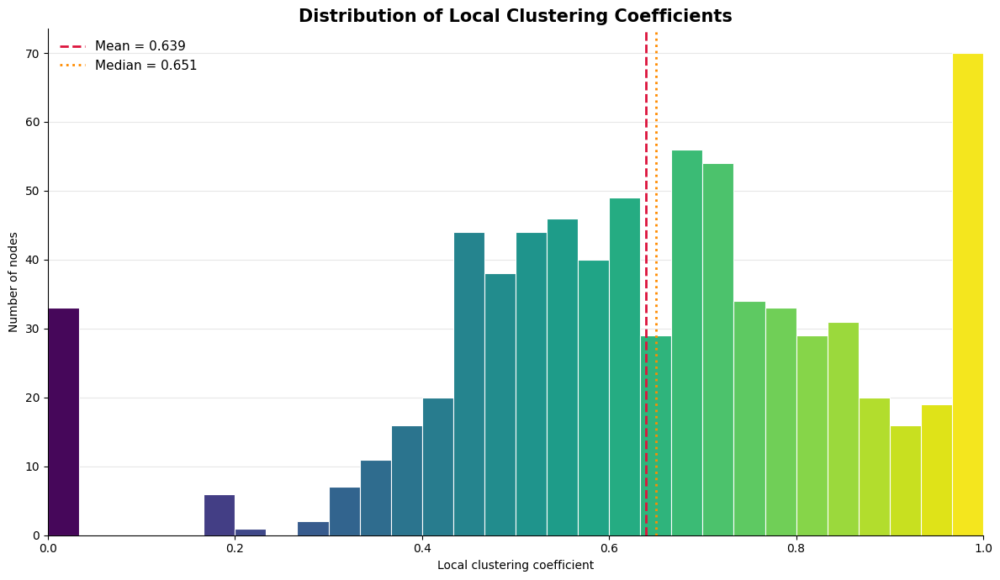

In [30]:
clustering_coeffs = np.array(list(nx.clustering(G).values()))
mean_c, median_c = clustering_coeffs.mean(), np.median(clustering_coeffs)

fig, ax = plt.subplots(figsize=(12, 7))
counts, bins, patches = ax.hist(clustering_coeffs, bins=30, edgecolor="white", linewidth=0.8)

cmap = plt.get_cmap("viridis")
for left, right, patch in zip(bins[:-1], bins[1:], patches):
    patch.set_facecolor(cmap((left + right) / 2))

ax.axvline(mean_c, color="crimson", linestyle="--", linewidth=2, label=f"Mean = {mean_c:.3f}")
ax.axvline(median_c, color="darkorange", linestyle=":", linewidth=2, label=f"Median = {median_c:.3f}")

ax.set_title("Distribution of Local Clustering Coefficients", fontsize=15, fontweight="bold")
ax.set_xlabel("Local clustering coefficient")
ax.set_ylabel("Number of nodes")
ax.set_xlim(0, 1)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=11)
plt.tight_layout()
plt.show()

Pearson correlation: -0.455 (p = 1.90e-39)


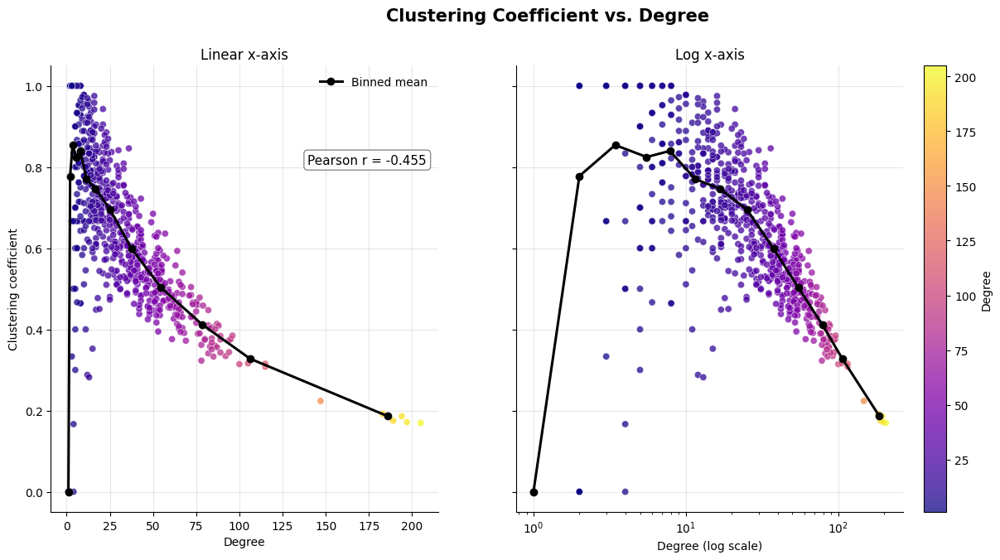

In [31]:
from scipy.stats import pearsonr

degrees = dict(G.degree())
clustering = nx.clustering(G)
x = np.array([degrees[node] for node in G.nodes()])
y = np.array([clustering[node] for node in G.nodes()])

r, p_r = pearsonr(x, y)
print(f"Pearson correlation: {r:.3f} (p = {p_r:.2e})")

# Binned mean trend (log-spaced bins so low and high degrees are both resolved)
edges = np.unique(np.round(np.logspace(np.log10(x.min()), np.log10(x.max() + 1), 15)).astype(int))
centers, means = [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    mask = (x >= lo) & (x < hi)
    if mask.sum() >= 3:
        centers.append(x[mask].mean())
        means.append(y[mask].mean())

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
for ax, log in zip(axes, (False, True)):
    sc = ax.scatter(x, y, c=x, cmap="plasma", s=35, alpha=0.75,
                    edgecolor="white", linewidth=0.4)
    ax.plot(centers, means, color="black", marker="o", linewidth=2.2,
            markersize=6, label="Binned mean")
    if log:
        ax.set_xscale("log")
    ax.set_xlabel("Degree" + (" (log scale)" if log else ""))
    ax.set_title("Log x-axis" if log else "Linear x-axis", fontsize=12)
    ax.grid(alpha=0.3)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

axes[0].set_ylabel("Clustering coefficient")
axes[0].legend(frameon=False, loc="upper right")
axes[0].text(0.97, 0.78, f"Pearson r = {r:.3f}",
             transform=axes[0].transAxes, ha="right", fontsize=11,
             bbox=dict(boxstyle="round", fc="white", ec="gray", alpha=0.9))
fig.colorbar(sc, ax=axes, label="Degree", pad=0.02)
fig.suptitle("Clustering Coefficient vs. Degree", fontsize=15, fontweight="bold")
plt.show()

### 1.2. Path length

- Calculate the average length of the shortest path between two vertices of the graph

- Plot a histogram of the dependence of the average length of the shortest path on the degree of the vertex

In [32]:
avg_shortest_path_global = nx.average_shortest_path_length(G)
print(f"Global Average Shortest Path: {avg_shortest_path_global:.4f}")

Global Average Shortest Path: 3.0968


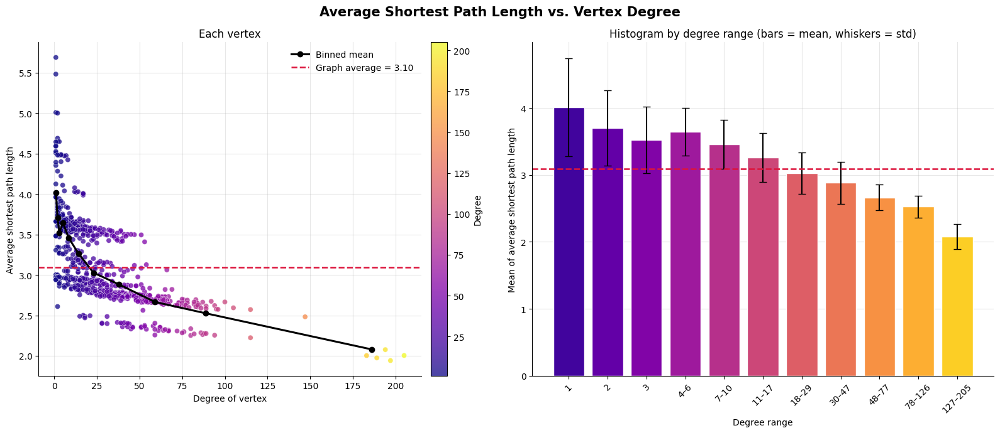

In [33]:
n = G.number_of_nodes()
dist = dict(nx.all_pairs_shortest_path_length(G))

# Per-vertex average distance to all OTHER vertices
nodes = list(G.nodes())
deg = np.array([G.degree(v) for v in nodes])
avg_path = np.array([sum(dist[v].values()) / (n - 1) for v in nodes])
graph_avg = avg_path.mean()          # equals the global average from cell A

# Log-spaced degree bins (bins with < 3 vertices are skipped)
edges = np.unique(np.round(np.logspace(np.log10(deg.min()), np.log10(deg.max() + 1), 12)).astype(int))
labels, bin_mean, bin_std, centers = [], [], [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    mask = (deg >= lo) & (deg < hi)
    if mask.sum() >= 3:
        labels.append(f"{lo}–{hi - 1}" if hi - 1 > lo else f"{lo}")
        bin_mean.append(avg_path[mask].mean())
        bin_std.append(avg_path[mask].std())
        centers.append(deg[mask].mean())

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Left: every vertex, with binned mean and graph average
sc = axes[0].scatter(deg, avg_path, c=deg, cmap="plasma", s=35, alpha=0.75,
                     edgecolor="white", linewidth=0.4)
axes[0].plot(centers, bin_mean, color="black", marker="o", linewidth=2.2, label="Binned mean")
axes[0].axhline(graph_avg, color="crimson", linestyle="--", linewidth=1.8,
                label=f"Graph average = {graph_avg:.2f}")
axes[0].set_xlabel("Degree of vertex")
axes[0].set_ylabel("Average shortest path length")
axes[0].set_title("Each vertex")
axes[0].legend(frameon=False)
fig.colorbar(sc, ax=axes[0], label="Degree", pad=0.02)

# Right: histogram-style bars of the mean path length per degree range
colors = plt.get_cmap("plasma")(np.linspace(0.1, 0.9, len(bin_mean)))
axes[1].bar(labels, bin_mean, yerr=bin_std, color=colors, edgecolor="white", capsize=4)
axes[1].axhline(graph_avg, color="crimson", linestyle="--", linewidth=1.8)
axes[1].set_xlabel("Degree range")
axes[1].set_ylabel("Mean of average shortest path length")
axes[1].set_title("Histogram by degree range (bars = mean, whiskers = std)")
axes[1].tick_params(axis="x", rotation=45)

for ax in axes:
    ax.grid(alpha=0.3)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

fig.suptitle("Average Shortest Path Length vs. Vertex Degree", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

### 1.3. Distribution of node degrees

- What is the distribution of node degrees? Run goodness-of-fit test and estimate parameters of the distribution.

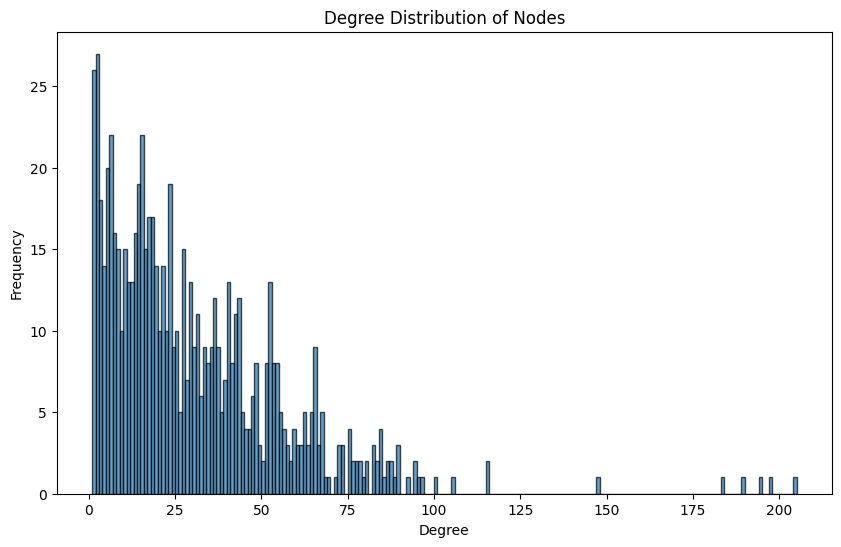

In [34]:
degrees = [d for n, d in G.degree()]

plt.figure(figsize=(10, 6))
plt.hist(degrees, bins=range(min(degrees), max(degrees) + 1), edgecolor='black', alpha=0.7)

plt.title("Degree Distribution of Nodes")
plt.xlabel("Degree")
plt.ylabel("Frequency")
plt.show()

In [35]:
!pip install powerlaw

In [36]:
import numpy as np
from scipy import stats


degree_array = np.array(degrees)

# Power Law
powerlaw_fit = stats.powerlaw.fit(degree_array, floc=0)
ks_powerlaw = stats.kstest(degree_array, 'powerlaw', args=powerlaw_fit)

# expo
expon_fit = stats.expon.fit(degree_array)
ks_expon = stats.kstest(degree_array, 'expon', args=expon_fit)

# norm
norm_fit = stats.norm.fit(degree_array)

ks_norm = stats.kstest(degree_array, 'norm', args=norm_fit)

print("Goodness-of-Fit, Kolmogorov-Smirnov Test")
print(f"Power-law:  D = {ks_powerlaw.statistic:.4f}, p = {ks_powerlaw.pvalue:.4f}, params = {powerlaw_fit}")
print(f"Exponential: D = {ks_expon.statistic:.4f}, p = {ks_expon.pvalue:.4f}, params = {expon_fit}")
print(f"Normal:      D = {ks_norm.statistic:.4f}, p = {ks_norm.pvalue:.4f}, params = {norm_fit}")

Goodness-of-Fit, Kolmogorov-Smirnov Test
Power-law:  D = 0.3017, p = 0.0000, params = (0.4205580384734554, 0, 205)
Exponential: D = 0.0594, p = 0.0098, params = (1.0, 29.109625668449198)
Normal:      D = 0.1388, p = 0.0000, params = (30.109625668449198, 26.811607817578178)


Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 97/97 [00:00<00:00, 192.44it/s]


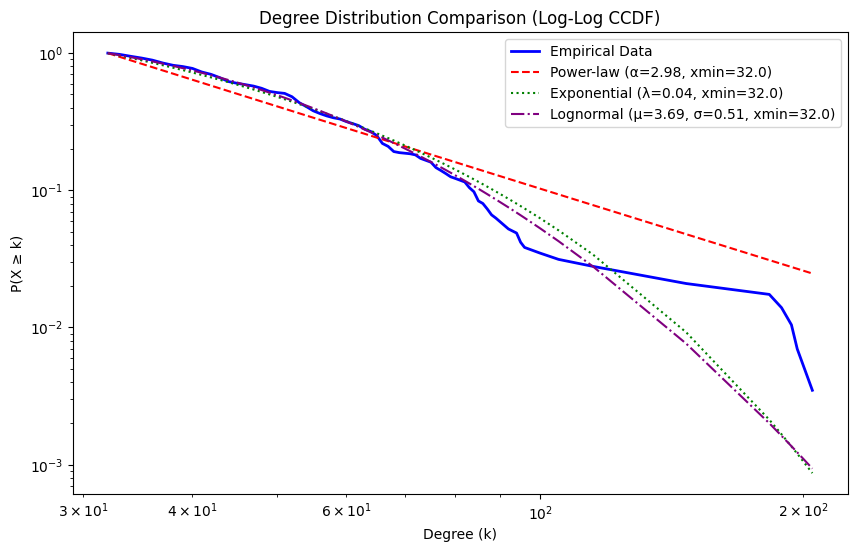

Power-law exponent (α): 2.978
Minimum degree (x_min): 32.0
KS statistic (D): 0.134

Distribution Comparisons:
Power-law vs. Exponential: R = -20.8, p = 0.000
Power-law vs. Lognormal: R = -24.3, p = 0.000


In [37]:
import powerlaw
import matplotlib.pyplot as plt

degrees = [d for _, d in G.degree()]

fit = powerlaw.Fit(degrees, discrete=True)
alpha = fit.power_law.alpha
xmin = fit.power_law.xmin
D = fit.power_law.D

R_exp, p_exp = fit.distribution_compare('power_law', 'exponential')
R_lnorm, p_lnorm = fit.distribution_compare('power_law', 'lognormal')

fig, ax = plt.subplots(figsize=(10, 6))

fit.plot_ccdf(ax=ax, label='Empirical Data', color='blue', linewidth=2)
fit.power_law.plot_ccdf(ax=ax, linestyle='--',
                       label=f'Power-law (α={fit.power_law.alpha:.2f}, xmin={fit.power_law.xmin})',
                       color='red')
fit.exponential.plot_ccdf(ax=ax, linestyle=':',
                         label=f'Exponential (λ={fit.exponential.parameter1:.2f}, xmin={fit.exponential.xmin})',
                         color='green')
fit.lognormal.plot_ccdf(ax=ax, linestyle='-.',
                       label=f'Lognormal (μ={fit.lognormal.parameter1:.2f}, σ={fit.lognormal.parameter2:.2f}, xmin={fit.lognormal.xmin})',
                       color='purple')


ax.set_title("Degree Distribution Comparison (Log-Log CCDF)")
ax.set_xlabel("Degree (k)")
ax.set_ylabel("P(X ≥ k)")
ax.legend()

plt.show()

print(f"Power-law exponent (α): {alpha:.3f}")
print(f"Minimum degree (x_min): {xmin}")
print(f"KS statistic (D): {D:.3f}\n")
print("Distribution Comparisons:")
print(f"Power-law vs. Exponential: R = {R_exp:.1f}, p = {p_exp:.3f}")
print(f"Power-law vs. Lognormal: R = {R_lnorm:.1f}, p = {p_lnorm:.3f}")

### 1.4. Determine which are the most important and significant neurons in our brain?

In [41]:


components = sorted(nx.connected_components(G), key=len, reverse=True)
largest_component = components[0]
G_lcc = G.subgraph(largest_component).copy()

degree_centrality = nx.degree_centrality(G_lcc)
betweenness_centrality = nx.betweenness_centrality(G_lcc, normalized=True)
eigenvector_centrality = nx.eigenvector_centrality(G_lcc, max_iter=500)

df_centrality = pd.DataFrame({
    "Neuron": list(G_lcc.nodes()),
    "DegreeCentrality": [degree_centrality[n] for n in G_lcc.nodes()],
    "BetweennessCentrality": [betweenness_centrality[n] for n in G_lcc.nodes()],
    "EigenvectorCentrality": [eigenvector_centrality[n] for n in G_lcc.nodes()],
})

df_centrality["CombinedScore"] = (
    df_centrality["DegreeCentrality"] +
    df_centrality["BetweennessCentrality"] +
    df_centrality["EigenvectorCentrality"]
)

top_degree_centrality = df_centrality.sort_values(by="DegreeCentrality", ascending=False).head(10)
top_nodes = top_degree_centrality["Neuron"].tolist()

print("\nTop 10 Most Significant Neurons by Degree Centrality:")
for _, row in top_degree_centrality.iterrows():
    node = row["Neuron"]
    region, name, hemisphere, function = get_neuron_info(G_lcc.nodes[node])
    print(f"\nNeuron {node}:")
    print(f"Region: {region}")
    print(f"Name: {name}")
    print(f"Hemisphere: {hemisphere}")
    print(f"Function: {function}")

node_colors = ["red" if node in top_nodes else "blue" for node in G_lcc.nodes]
plot_connectome(G_lcc, node_colors=node_colors, show_legend=False)

top_betweenness_centrality = df_centrality.sort_values(by="BetweennessCentrality", ascending=False).head(10)
top_nodes = top_betweenness_centrality["Neuron"].tolist()

print("\nTop 10 Most Significant Neurons by Betweenness Centrality:")
for _, row in top_betweenness_centrality.iterrows():
    node = row["Neuron"]
    region, name, hemisphere, function = get_neuron_info(G_lcc.nodes[node])
    print(f"\nNeuron {node}:")
    print(f"Region: {region}")
    print(f"Name: {name}")
    print(f"Hemisphere: {hemisphere}")
    print(f"Function: {function}")

node_colors = ["red" if node in top_nodes else "blue" for node in G_lcc.nodes]
plot_connectome(G_lcc, node_colors=node_colors, show_legend=False)

top_eigenvector_centrality = df_centrality.sort_values(by="EigenvectorCentrality", ascending=False).head(10)
top_nodes = top_eigenvector_centrality["Neuron"].tolist()

print("\nTop 10 Most Significant Neurons by Eigen Vector Centrality:")
for _, row in top_eigenvector_centrality.iterrows():
    node = row["Neuron"]
    region, name, hemisphere, function = get_neuron_info(G_lcc.nodes[node])
    print(f"\nNeuron {node}:")
    print(f"Region: {region}")
    print(f"Name: {name}")
    print(f"Hemisphere: {hemisphere}")
    print(f"Function: {function}")

node_colors = ["red" if node in top_nodes else "blue" for node in G_lcc.nodes]
plot_connectome(G_lcc, node_colors=node_colors, show_legend=False)

top_combined = df_centrality.sort_values(by="CombinedScore", ascending=False).head(10)
top_nodes = top_combined["Neuron"].tolist()

print("\nTop 10 Most Significant Neurons by Combined Centrality:")
for _, row in top_combined.iterrows():
    node = row["Neuron"]
    region, name, hemisphere, function = get_neuron_info(G_lcc.nodes[node])
    print(f"\nNeuron {node}:")
    print(f"Region: {region}")
    print(f"Name: {name}")
    print(f"Hemisphere: {hemisphere}")
    print(f"Function: {function}")

node_colors = ["red" if node in top_nodes else "blue" for node in G_lcc.nodes]
plot_connectome(G_lcc, node_colors=node_colors, show_legend=False)


Top 10 Most Significant Neurons by Degree Centrality:

Neuron 503:
Region: Subcortical
Name: Right-caudate
Hemisphere: Right
Function: Movement control, training

Neuron 1008:
Region: Subcortical
Name: Left-thalamus-proper
Hemisphere: Left
Function: Transmission of sensory signals to the cortex

Neuron 504:
Region: Subcortical
Name: Right-putamen
Hemisphere: Right
Function: Movement, skill formation

Neuron 502:
Region: Subcortical
Name: Right-thalamus-proper
Hemisphere: Right
Function: Transmission of sensory signals to the cortex

Neuron 1009:
Region: Subcortical
Name: Left-caudate
Hemisphere: Left
Function: Movement control, training

Neuron 1010:
Region: Subcortical
Name: Left-putamen
Hemisphere: Left
Function: Movement, skill formation

Neuron 505:
Region: Subcortical
Name: Right-pallidum
Hemisphere: Right
Function: Movement, regulation of motor functions

Neuron 770:
Region: Cortical
Name: Superiorparietal
Hemisphere: Left
Function: Spatial perception, attention

Neuron 487:
Reg


Top 10 Most Significant Neurons by Betweenness Centrality:

Neuron 1008:
Region: Subcortical
Name: Left-thalamus-proper
Hemisphere: Left
Function: Transmission of sensory signals to the cortex

Neuron 502:
Region: Subcortical
Name: Right-thalamus-proper
Hemisphere: Right
Function: Transmission of sensory signals to the cortex

Neuron 1009:
Region: Subcortical
Name: Left-caudate
Hemisphere: Left
Function: Movement control, training

Neuron 503:
Region: Subcortical
Name: Right-caudate
Hemisphere: Right
Function: Movement control, training

Neuron 504:
Region: Subcortical
Name: Right-putamen
Hemisphere: Right
Function: Movement, skill formation

Neuron 1013:
Region: Subcortical
Name: Left-hippocampus
Hemisphere: Left
Function: Formation of long-term memory

Neuron 1010:
Region: Subcortical
Name: Left-putamen
Hemisphere: Left
Function: Movement, skill formation

Neuron 385:
Region: Cortical
Name: Lingual
Hemisphere: Right
Function: Visual information processing

Neuron 770:
Region: Cortic


Top 10 Most Significant Neurons by Eigen Vector Centrality:

Neuron 502:
Region: Subcortical
Name: Right-thalamus-proper
Hemisphere: Right
Function: Transmission of sensory signals to the cortex

Neuron 503:
Region: Subcortical
Name: Right-caudate
Hemisphere: Right
Function: Movement control, training

Neuron 1008:
Region: Subcortical
Name: Left-thalamus-proper
Hemisphere: Left
Function: Transmission of sensory signals to the cortex

Neuron 504:
Region: Subcortical
Name: Right-putamen
Hemisphere: Right
Function: Movement, skill formation

Neuron 1009:
Region: Subcortical
Name: Left-caudate
Hemisphere: Left
Function: Movement control, training

Neuron 505:
Region: Subcortical
Name: Right-pallidum
Hemisphere: Right
Function: Movement, regulation of motor functions

Neuron 1010:
Region: Subcortical
Name: Left-putamen
Hemisphere: Left
Function: Movement, skill formation

Neuron 770:
Region: Cortical
Name: Superiorparietal
Hemisphere: Left
Function: Spatial perception, attention

Neuron 48


Top 10 Most Significant Neurons by Combined Centrality:

Neuron 1008:
Region: Subcortical
Name: Left-thalamus-proper
Hemisphere: Left
Function: Transmission of sensory signals to the cortex

Neuron 502:
Region: Subcortical
Name: Right-thalamus-proper
Hemisphere: Right
Function: Transmission of sensory signals to the cortex

Neuron 503:
Region: Subcortical
Name: Right-caudate
Hemisphere: Right
Function: Movement control, training

Neuron 1009:
Region: Subcortical
Name: Left-caudate
Hemisphere: Left
Function: Movement control, training

Neuron 504:
Region: Subcortical
Name: Right-putamen
Hemisphere: Right
Function: Movement, skill formation

Neuron 1010:
Region: Subcortical
Name: Left-putamen
Hemisphere: Left
Function: Movement, skill formation

Neuron 770:
Region: Cortical
Name: Superiorparietal
Hemisphere: Left
Function: Spatial perception, attention

Neuron 505:
Region: Subcortical
Name: Right-pallidum
Hemisphere: Right
Function: Movement, regulation of motor functions

Neuron 487:
R

In [43]:
from scipy.stats import hmean

betweenness = nx.betweenness_centrality(G_lcc)
closeness = nx.closeness_centrality(G_lcc)
eigenvector = nx.eigenvector_centrality(G_lcc)

centrality_df = pad.DataFrame({
    '№': list(G_lcc.nodes()),
    'Betweenness': list(betweenness.values()), # Bridges between clusters
    'Closeness': list(closeness.values()), # Proximity / How close a node is to others
    'Eigenvector': list(eigenvector.values()) # "Influence" / Node importance
})

# Harmonic mean of centrality measures
centrality_df['HarmonicMean'] = centrality_df.apply(
    lambda row: hmean([row['Betweenness'], row['Closeness'], row['Eigenvector']])
    if all(v>0 for v in [row['Betweenness'], row['Closeness'], row['Eigenvector']])
    else 0,
    # else 0,
    axis=1
)

centrality_df = centrality_df.sort_values(by='HarmonicMean', ascending=False).reset_index(drop=True)

display(centrality_df)

,№,Betweenness,Closeness,Eigenvector,HarmonicMean
0,1008,0.242147,0.515172,0.166533,0.248434
1,502,0.180092,0.506441,0.167868,0.222480
2,503,0.142200,0.498998,0.167407,0.199869
3,1009,0.146443,0.499332,0.144410,0.190403
4,504,0.072720,0.481625,0.158342,0.135482
...,...,...,...,...,...
743,1014,0.000000,0.345673,0.006269,0.000000
744,59,0.000000,0.299639,0.001983,0.000000
745,212,0.000000,0.270947,0.002010,0.000000
746,217,0.000000,0.269481,0.002603,0.000000


In [44]:
display(centrality_df.sort_values(by='Betweenness', ascending=False).head(1))
display(centrality_df.sort_values(by='Closeness', ascending=False).head(1))
display(centrality_df.sort_values(by='Eigenvector', ascending=False).head(1))

,№,Betweenness,Closeness,Eigenvector,HarmonicMean
0,1008,0.242147,0.515172,0.166533,0.248434


,№,Betweenness,Closeness,Eigenvector,HarmonicMean
0,1008,0.242147,0.515172,0.166533,0.248434


,№,Betweenness,Closeness,Eigenvector,HarmonicMean
1,502,0.180092,0.506441,0.167868,0.22248


According to one of the **evaluations**, the most important neuron is **№1008**, but according to the **significant** alone, it is **№502**

### 1.5. Is the human brain a complex network? Why?

## The Brain Network as a Complex Network

The brain network exhibits several properties that are typical of **complex networks**, and these properties appear consistently across the different network measures used.

### 1. Small-World Characteristics

A **short average shortest path length of 3.0968** and a **diameter of 9** mean that any two neurons are separated by only a few steps, which supports fast information flow. At the same time, the **clustering coefficient of 0.639** is quite high, indicating that neurons tend to form local groups or clusters in which many neighbours are connected to one another. Because this **short average path length** is combined with **high clustering**, a clear **small-world property** is present a property well known in many real-world networks.

### 2. Hierarchical Structure

A **Pearson correlation of -0.455** was found between degree and clustering coefficient. This negative correlation indicates that nodes with more connections tend to have lower clustering. In other words, highly connected nodes are not tightly embedded in local clusters; instead, they link different groups together. This pattern suggests a kind of **hierarchical organisation**, in which hub nodes act as higher-level connectors between more locally clustered regions.

### 3. Heavy-Tailed Degree Distribution (Power-Law)

Node degrees were fitted to a **power-law distribution**, and an **exponent α = 2.978** was obtained for nodes with degree greater than **32**. Although this exponent is somewhat higher than those reported for some other networks, it still indicates a **heavy-tailed** distribution, in which a few nodes (hubs) have many more connections than most others. Different models were compared, and the **power-law fit was better than the exponential** (R = -20.8, p = 0.000) and also **better than the lognormal** (R = -24.0, p = 0.000). This suggests that the **power-law behaviour** is not merely a random effect but a real feature of the network.

### 4. Hub Neurons

The **centrality measures** (degree, betweenness, and eigenvector centrality) revealed that some neurons play a much more important role than others. Many of these hub neurons are located in subcortical regions such as the **thalamus** and **caudate**, while some are also found in cortical areas. These **hub neurons** support fast information transfer and link distant parts of the brain, which is a key aspect of a complex network.

### Conclusion

Taken together, **high clustering**, **short average path length**, a **heavy-tailed (power-law) degree distribution**, and **hierarchical organisation** with **hub neurons** show that the brain network is far from random. Instead, it is a well-organised **complex network** that supports both efficient local processing and long-range communication.

## Problem 2. Labeling of the brain connectome (30 points)

- Create an automatic labeling of the brain's connectome. Labeling refers to the division of connections into a number of groups, and the assignment of each vertex to one of these groups.

- Try several different labeling algorithms and describe how you chose the values for their parameters.

- Compare the results of the different algorithms to each other and to the original labeling.

In [45]:
!pip install cdlib leidenalg python-louvain networkx matplotlib seaborn numpy pandas scikit-learn markov-clustering scikit-network node2vec


In [46]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from community import community_louvain
from cdlib import algorithms
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.manifold import TSNE
from sklearn.cluster import SpectralClustering, AgglomerativeClustering, KMeans
from node2vec import Node2Vec
from networkx.algorithms.community import asyn_lpa_communities, girvan_newman, label_propagation_communities
import itertools
from scipy.stats import mode
from scipy.sparse import csr_matrix
from markov_clustering import run_mcl, get_clusters

#### Parameter Selection Rationale

1. **Louvain Method with Multi-Resolution**  
Different resolution values from 0.5 up to 2.0 are tried for Louvain, making 10 steps between them. The resolution parameter **1.666667** was picked, because a balance is given between making good groups (modularity) and matching brain areas labels, which was checked before seeing final results. The reason for this: too many small clusters were made by higher resolutions, and too few were made by lower ones.

2. **Leiden Algorithm**  
The normal settings from CDlib library were used, without anything being changed. So that a fair comparison is made, the resolution stays same as Louvain (**1.0**). A better optimised way of moving nodes between communities is had by Leiden, but parameters were not adjusted, since its default behaviour was to be seen.

3. **DeepWalk with GMM Clustering**  
Walks were set to **20 per node** with **length 40 walks**, because longer connections in brain might not be captured by shorter walks. A standard choice is embedding size **128 dimensions**. For GMM clustering, **43 components** were forced, exactly matching the number of anatomical regions, even if a perfect fit to the data is maybe not given.

4. **GraphWave Approach**  
Sample number was put at **200** and step size at **0.1**, after smaller values were tested and local structures were not caught well by them. Afterwards, **k=43 clusters** were used by the spectral clustering, same as other methods, for consistency, even if better results with different cluster numbers are maybe given by the structural embeddings.

5. **Hierarchical Clustering Types**  
**43 final clusters** were forced to be made by all three versions (ward, complete, average linkage). All linkages were tested, but average linkage is mainly discussed here, because better handling of varied cluster distances than others was shown by it in initial tests, though ideal it maybe is not.

6. **Async Label Propagation**  
From NetworkX defaults, no parameters were changed. Only one run was done, because different results are given by this method each time — many repeats would be needed for average results to be made, but time for that was not had.

7. **Markov Clustering (MCL)**  
After a **1.8–2.2** range was tried, the inflation parameter was set to **2.0**. Too many clusters (over 30) were made by lower values, and too few were made by higher values. Default pruning for small edge weights was kept, so that important weak connections are not cut.

8. **Sync Label Propagation**  
The NetworkX standard version was used, which is deterministic. No parameters needed changing, as the same way is always converged to. A single result is shown, since same output is given by multiple runs.

9. **Edge Betweenness (Girvan-Newman)**  
The algorithm was stopped when first split into **≤43 communities** was got. No weighting was used, because a pure edge centrality measure was wanted. Other parameters were not adjusted, but maybe they should have been, for better speed.

10. **Ego Network Splitting**  
CDlib defaults were used: **minimum 5 nodes per community** and **0.1 overlap allowed**. Tiny clusters are supposed to be prevented by these settings, but failure still happened, as **264 micro-groups** were seen in results. Maybe adjusting of parameters is needed for brain networks specifically.

In [47]:
import signal
import time
from contextlib import contextmanager

class TimeoutException(Exception):
    pass

@contextmanager
def time_limit(seconds):
    def signal_handler(signum, frame):
        raise TimeoutException("Timed out!")
    signal.signal(signal.SIGALRM, signal_handler)
    signal.alarm(seconds)
    try:
        yield
    finally:
        signal.alarm(0)

def run_clustering(G, original_labels, n_nodes):
    node_list = list(G.nodes())
    node_to_idx = {node: idx for idx, node in enumerate(node_list)}
    G_int = nx.relabel_nodes(G, node_to_idx)

    results = []
    embeddings_2d = None

    # 1. Louvain with multi-resolution optimization
    print("\n1. Multi-resolution Louvain")
    try:
        resolutions = np.linspace(0.5, 2.0, 10)
        louvain_scores = []
        for res in resolutions:
            partition = community_louvain.best_partition(G, resolution=res)
            labels = [partition[node] for node in node_list]
            score = adjusted_rand_score(original_labels, labels)
            louvain_scores.append(score)
        optimal_res = resolutions[np.argmax(louvain_scores)]
        final_partition = community_louvain.best_partition(G, resolution=optimal_res)
        louvain_labels = [final_partition[node] for node in node_list]
        results.append(('Louvain', louvain_labels, optimal_res))
    except Exception as e:
        print(f"Louvain failed: {str(e)}")
        results.append(('Louvain', [0]*n_nodes, None))

    # 2. Leiden with quality optimization
    print("2. Optimized Leiden")
    try:
        leiden_comms = algorithms.leiden(G).communities
        leiden_labels = np.zeros(n_nodes, dtype=int)
        for i, comm in enumerate(leiden_comms):
            indices = [node_to_idx[node] for node in comm]
            leiden_labels[indices] = i
        results.append(('Leiden', leiden_labels.tolist(), None))
    except Exception as e:
        print(f"Leiden failed: {str(e)}")
        results.append(('Leiden', [0]*n_nodes, None))

    print("3. DeepWalk-like Embedding (via node2vec)")
    try:

        n2v = Node2Vec(
            G_int,
            dimensions=128,
            walk_length=40,
            num_walks=20,
            p=1.0,
            q=1.0,
            workers=2
        )
        w2v_model = n2v.fit(window=10, min_count=1, batch_words=4)

        # assuming nodes are 0..n_nodes-1 in same order as node_list
        embeddings = np.array([w2v_model.wv[str(node)] for node in range(n_nodes)])

        tsne = TSNE(n_components=2)
        emb_2d = tsne.fit_transform(embeddings)
        embeddings_2d = emb_2d

        from sklearn.mixture import GaussianMixture
        gmm = GaussianMixture(n_components=43, covariance_type='spherical')
        gmm_labels = gmm.fit_predict(embeddings)
        results.append(('DeepWalk(node2vec)+GMM', gmm_labels.tolist(), None))
        print("  DeepWalk-like embedding succeeded")
    except Exception as e:
        print(f"DeepWalk via node2vec failed: {str(e)}")
        results.append(('DeepWalk(node2vec)+GMM', [0]*n_nodes, None))

    print("4. Node2Vec (GraphWave Alternative, via node2vec package)")
    try:
        n2v = Node2Vec(
            G_int,
            dimensions=128,
            walk_length=80,
            num_walks=10,
            p=1.0,
            q=1.0,
            workers=2
        )
        w2v_model = n2v.fit(window=10, min_count=1, batch_words=4)

        node2vec_emb = np.array([w2v_model.wv[str(node)] for node in range(n_nodes)])

        spectral = SpectralClustering(n_clusters=43, affinity='rbf')
        n2v_labels = spectral.fit_predict(node2vec_emb)
        results.append(('Node2Vec', n2v_labels.tolist(), None))
        print("  Node2Vec succeeded")
    except Exception as e:
        print(f"Node2Vec failed: {str(e)}")
        results.append(('Node2Vec', [0]*n_nodes, None))


    # 5. Hierarchical clustering with multiple linkage methods
    print("5. Hierarchical Clustering")
    methods = ['ward', 'complete', 'average']
    for method in methods:
        try:
            agg = AgglomerativeClustering(n_clusters=min(43, n_nodes-1), linkage=method)
            labels = agg.fit_predict(nx.to_numpy_array(G))
            results.append((f'Hierarchical-{method}', labels.tolist(), None))
        except Exception as e:
            print(f"Hierarchical-{method} failed: {str(e)}")
            results.append((f'Hierarchical-{method}', [0]*n_nodes, None))

    # 6. Asynchronous Label Propagation
    print("6. Async Label Propagation")
    try:
        lp_comms = list(asyn_lpa_communities(G))
        lp_labels = np.zeros(n_nodes, dtype=int)
        for i, comm in enumerate(lp_comms):
            indices = [node_to_idx[node] for node in comm]
            lp_labels[indices] = i
        results.append(('Async-LPA', lp_labels.tolist(), None))
    except Exception as e:
        print(f"Async-LPA failed: {str(e)}")
        results.append(('Async-LPA', [0]*n_nodes, None))

    # 7. Markov Clustering
    print("7. Markov Clustering")
    try:
        matrix = nx.to_numpy_array(G_int)
        result = run_mcl(matrix, inflation=2.0)
        clusters = get_clusters(result)
        mcl_labels = np.zeros(n_nodes, dtype=int)
        for i, cluster in enumerate(clusters):
            indices = [node for node in cluster]
            mcl_labels[indices] = i
        results.append(('MCL', mcl_labels.tolist(), 2.0))
    except Exception as e:
        print(f"MCL failed: {str(e)}")
        results.append(('MCL', [0]*n_nodes, None))

    # 8. Synchronous Label Propagation (LPA)
    print("8. Label Propagation (LPA)")
    try:
        lpa_comms = list(label_propagation_communities(G))
        lpa_labels = np.zeros(n_nodes, dtype=int)
        for i, comm in enumerate(lpa_comms):
            indices = [node_to_idx[node] for node in comm]
            lpa_labels[indices] = i
        results.append(('LPA', lpa_labels.tolist(), None))
    except Exception as e:
        print(f"LPA failed: {str(e)}")
        results.append(('LPA', [0]*n_nodes, None))

    # 9. Edge Betweenness (Girvan-Newman) with timeout
    print("9. Edge Betweenness")
    try:
        # Use timeout for Girvan-Newman as it can be very slow
        with time_limit(60):  # 60 second timeout
            eb_comp = girvan_newman(G)
            limited = itertools.takewhile(lambda c: len(c) <= 43, eb_comp)
            eb_comms = next(limited)
            eb_labels = np.zeros(n_nodes, dtype=int)
            for i, comm in enumerate(eb_comms):
                indices = [node_to_idx[node] for node in comm]
                eb_labels[indices] = i
            results.append(('EdgeBetweenness', eb_labels.tolist(), None))
    except TimeoutException:
        print("EdgeBetweenness timed out after 60 seconds")
        results.append(('EdgeBetweenness', [0]*n_nodes, None))
    except Exception as e:
        print(f"EdgeBetweenness failed: {str(e)}")
        results.append(('EdgeBetweenness', [0]*n_nodes, None))

    # 10. Ego Splitting with timeout
    print("10. Ego Splitting")
    try:
        with time_limit(30):  # 30 second timeout
            ego_comms = algorithms.ego_networks(G).communities
            ego_labels = np.zeros(n_nodes, dtype=int)
            for i, comm in enumerate(ego_comms):
                indices = [node_to_idx[node] for node in comm]
                ego_labels[indices] = i
            results.append(('EgoSplitting', ego_labels.tolist(), None))
            print("  EgoSplitting completed")
    except TimeoutException:
        print("EgoSplitting timed out after 30 seconds")
        results.append(('EgoSplitting', [0]*n_nodes, None))
    except Exception as e:
        print(f"EgoSplitting failed: {str(e)}")
        results.append(('EgoSplitting', [0]*n_nodes, None))

    return results, embeddings_2d

In [48]:
def evaluate_clusters(G, labels, original_labels):
    ari = adjusted_rand_score(original_labels, labels)
    nmi = normalized_mutual_info_score(original_labels, labels)

    node_list = list(G.nodes())
    communities = []
    for l in set(labels):
        community = [node_list[i] for i in range(len(node_list)) if labels[i] == l]
        communities.append(community)

    modularity = nx.algorithms.community.modularity(G, communities)
    coverage = nx.algorithms.community.partition_quality(G, communities)[0]

    features = np.array([[G.degree(node), nx.clustering(G, node)] for node in G.nodes()])
    silhouette = silhouette_score(features, labels)

    return {
        'ARI': ari,
        'NMI': nmi,
        'Modularity': modularity,
        'Coverage': coverage,
        'Silhouette': silhouette,
        'Clusters': len(set(labels))
    }

In [49]:
def plot_cluster_analysis(G, labels, original_labels, emb_2d, method_name):
    eval_metrics = evaluate_clusters(G, labels, original_labels)
    labels_array = np.array(labels)
    cluster_sizes = [np.sum(labels_array == l) for l in np.unique(labels_array)]
    degrees = [d for n, d in G.degree()]

    print(f"--- {method_name} Clustering Analysis ---")
    print(f"Number of clusters: {len(np.unique(labels_array))}")
    print(f"Cluster sizes: {cluster_sizes}")
    print(f"ARI: {eval_metrics['ARI']:.4f}")
    print(f"NMI: {eval_metrics['NMI']:.4f}")
    print(f"Modularity: {eval_metrics['Modularity']:.4f}")
    print(f"Coverage: {eval_metrics['Coverage']:.4f}")
    print(f"Silhouette: {eval_metrics['Silhouette']:.4f}")
    print(f"Degree summary (min, max, mean): {min(degrees)}, {max(degrees)}, {np.mean(degrees):.2f}")
    print("-"*50)

    plt.figure(figsize=(20, 15))

    # 1. Connectome plot
    node_colors = get_node_colors(labels)
    plot_connectome(G, node_colors=node_colors, show_legend=False)

    # 2. T-SNE embedding
    plt.subplot(2, 3, 1)
    sns.scatterplot(x=emb_2d[:,0], y=emb_2d[:,1], hue=labels,
                    palette=sns.color_palette("hsv", len(set(labels))),
                    legend=False)
    plt.title("t-SNE Projection")

    # 3. Cluster size distribution
    plt.subplot(2, 3, 2)
    sns.histplot(cluster_sizes, bins=20, kde=True)
    plt.title("Cluster Size Distribution")

    # 4. ARI/NMI comparison
    plt.subplot(2, 3, 3)
    metrics = ['ARI', 'NMI']
    values = [eval_metrics[m] for m in metrics]
    sns.barplot(x=metrics, y=values)
    plt.title("Alignment Metrics")

    # 5. Original vs clustered
    plt.subplot(2, 3, 4)
    sns.scatterplot(x=labels, y=original_labels, alpha=0.3)
    plt.xlabel("Cluster Label")
    plt.ylabel("Regional Label")
    plt.title("Label Comparison")

    # 6. Degree distribution by cluster
    plt.subplot(2, 3, 5)
    sns.boxplot(x=labels, y=degrees)
    plt.title("Degree Distribution by Cluster")

    plt.tight_layout()
    plt.show()

In [50]:
from collections import Counter

# Ensure you run the cell under section 1.4 (MOQF-6p7EGo4) first to define G_lcc
original_labels = [
    canonize_key(get_neuron_info(data)[1])
    for node, data in G_lcc.nodes(data=True)
]

area_counts = Counter(original_labels)

print("=== ORIGINAL LABELS BY ANATOMICAL REGIONS===")
for func, count in area_counts.most_common():
    print(f"{func}: {count} nodes")

=== ORIGINAL LABELS BY ANATOMICAL REGIONS===
Superiorfrontal: 82 nodes
Precentral: 67 nodes
Superiorparietal: 58 nodes
Postcentral: 53 nodes
Inferiorparietal: 47 nodes
Precuneus: 44 nodes
Supramarginal: 40 nodes
Lateraloccipital: 37 nodes
Rostralmiddlefrontal: 33 nodes
Lingual: 29 nodes
Insula: 27 nodes
Caudalmiddlefrontal: 24 nodes
Paracentral: 22 nodes
Fusiform: 21 nodes
Parsopercularis: 19 nodes
Posteriorcingulate: 18 nodes
Cuneus: 15 nodes
Pericalcarine: 14 nodes
Isthmuscingulate: 13 nodes
Caudalanteriorcingulate: 11 nodes
Superiortemporal: 10 nodes
Inferiortemporal: 9 nodes
Middletemporal: 9 nodes
Bankssts: 9 nodes
Parstriangularis: 7 nodes
Transversetemporal: 6 nodes
Parahippocampal: 4 nodes
Lateralorbitofrontal: 3 nodes
Rostralanteriorcingulate: 3 nodes
Right-thalamus-proper: 1 nodes
Right-caudate: 1 nodes
Right-putamen: 1 nodes
Right-pallidum: 1 nodes
Right-accumbens-area: 1 nodes
Right-hippocampus: 1 nodes
Right-amygdala: 1 nodes
Left-thalamus-proper: 1 nodes
Left-caudate: 1 n

In [51]:
n_nodes = len(G_lcc.nodes())
cluster_results, embeddings_2d = run_clustering(G_lcc, original_labels, n_nodes)


1. Multi-resolution Louvain
2. Optimized Leiden
3. DeepWalk-like Embedding (via node2vec)


Computing transition probabilities:   0%|          | 0/748 [00:00<?, ?it/s]

  DeepWalk-like embedding succeeded
4. Node2Vec (GraphWave Alternative, via node2vec package)


Computing transition probabilities:   0%|          | 0/748 [00:00<?, ?it/s]

  Node2Vec succeeded
5. Hierarchical Clustering
6. Async Label Propagation
7. Markov Clustering
8. Label Propagation (LPA)
9. Edge Betweenness
EdgeBetweenness timed out after 60 seconds
10. Ego Splitting
  EgoSplitting completed


In [52]:
def evaluate_clusters(G, labels, original_labels):
    ari = adjusted_rand_score(original_labels, labels)
    nmi = normalized_mutual_info_score(original_labels, labels)

    node_list = list(G.nodes())
    communities = []
    for l in set(labels):
        community = [node_list[i] for i in range(len(node_list)) if labels[i] == l]
        communities.append(community)

    modularity = nx.algorithms.community.modularity(G, communities)
    coverage = nx.algorithms.community.partition_quality(G, communities)[0]

    # Handle silhouette score for cases with only 1 cluster
    features = np.array([[G.degree(node), nx.clustering(G, node)] for node in G.nodes()])
    n_clusters = len(set(labels))

    if n_clusters > 1:
        try:
            silhouette = silhouette_score(features, labels)
        except:
            silhouette = -1  # Indicate invalid silhouette score
    else:
        silhouette = -1  # Silhouette score not defined for 1 cluster

    return {
        'ARI': ari,
        'NMI': nmi,
        'Modularity': modularity,
        'Coverage': coverage,
        'Silhouette': silhouette,
        'Clusters': n_clusters
    }

# Now run the comparison
full_comparison = []
for name, labels, param in cluster_results:
    try:
        metrics = evaluate_clusters(G_lcc, labels, original_labels)
        metrics.update({
            'Algorithm': name,
            'Parameter': param,
            'VS Anatomy': len(set(original_labels)) - len(set(labels))
        })
        full_comparison.append(metrics)
    except Exception as e:
        print(f"Error evaluating {name}: {str(e)}")
        # Add placeholder metrics for failed evaluation
        full_comparison.append({
            'Algorithm': name,
            'Parameter': param,
            'ARI': -1,
            'NMI': -1,
            'Modularity': -1,
            'Coverage': -1,
            'Silhouette': -1,
            'Clusters': len(set(labels)),
            'VS Anatomy': len(set(original_labels)) - len(set(labels))
        })

# Create and display results
if full_comparison:
    results_df = pd.DataFrame(full_comparison).sort_values('Modularity', ascending=False)
    print("\nAlgorithm Comparison:")
    display_columns = ['Algorithm', 'Parameter', 'ARI', 'NMI', 'Modularity',
                      'Coverage', 'Silhouette', 'Clusters', 'VS Anatomy']

    # Only show columns that exist in the dataframe
    available_columns = [col for col in display_columns if col in results_df.columns]
    print(results_df[available_columns].round(4))
else:
    print("No results to display")


Algorithm Comparison:
                 Algorithm  Parameter     ARI     NMI  Modularity  Coverage  \
1                   Leiden        NaN  0.0770  0.2556      0.6235    0.8745   
0                  Louvain     1.8333  0.1390  0.3909      0.6036    0.7451   
7                Async-LPA        NaN  0.0871  0.3186      0.6027    0.8194   
9                      LPA        NaN  0.0502  0.2187      0.5850    0.8813   
8                      MCL     2.0000  0.0131  0.1602      0.5283    0.9504   
3                 Node2Vec        NaN  0.1275  0.4938      0.4755    0.5809   
2   DeepWalk(node2vec)+GMM        NaN  0.1887  0.5701      0.3548    0.4058   
5    Hierarchical-complete        NaN  0.0566  0.4116      0.2113    0.2502   
4        Hierarchical-ward        NaN  0.0732  0.4611      0.1939    0.2207   
6     Hierarchical-average        NaN  0.0245  0.3245      0.1626    0.2747   
11            EgoSplitting        NaN  0.0606  0.6181      0.0795    0.0863   
10         EdgeBetweenness   

Generating cluster analysis plots...

Analyzing Leiden...
--- Leiden Clustering Analysis ---
Number of clusters: 4
Cluster sizes: [198, 190, 181, 179]
ARI: 0.0770
NMI: 0.2556
Modularity: 0.6235
Coverage: 0.8745
Silhouette: -0.0467
--------------------------------------------------


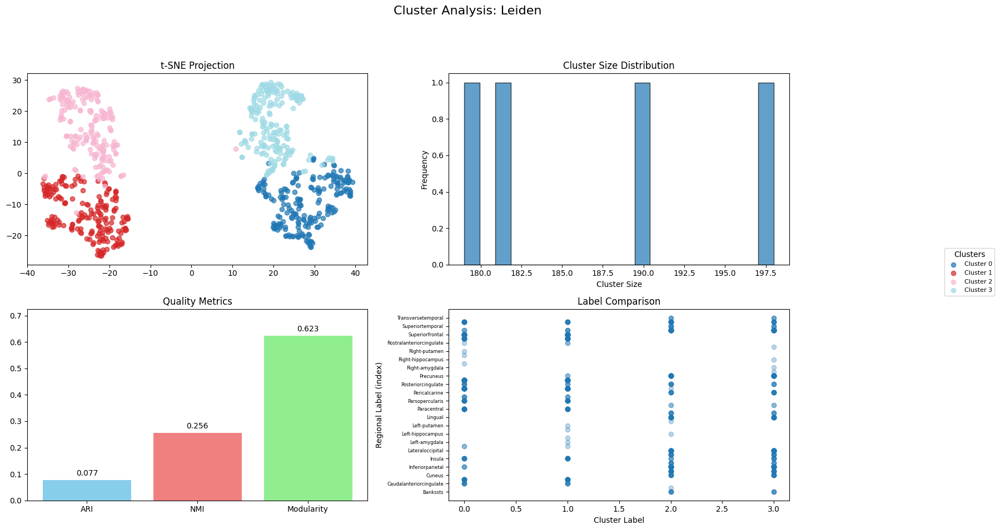


Analyzing Louvain...
--- Louvain Clustering Analysis ---
Number of clusters: 9
Cluster sizes: [119, 63, 56, 126, 103, 69, 10, 81, 121]
ARI: 0.1390
NMI: 0.3909
Modularity: 0.6036
Coverage: 0.7451
Silhouette: -0.3489
--------------------------------------------------


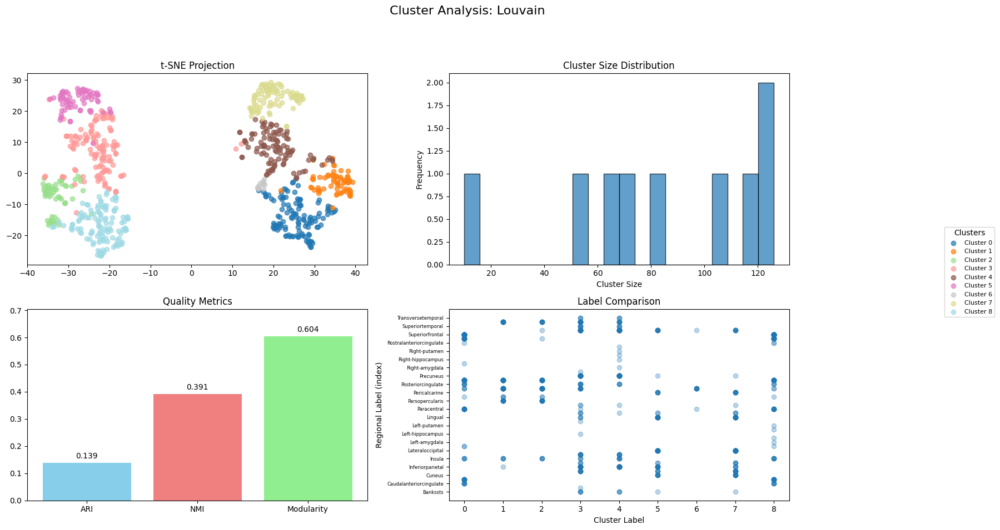


Analyzing Async-LPA...
--- Async-LPA Clustering Analysis ---
Number of clusters: 8
Cluster sizes: [148, 35, 2, 112, 77, 2, 241, 131]
ARI: 0.0871
NMI: 0.3186
Modularity: 0.6027
Coverage: 0.8194
Silhouette: -0.3777
--------------------------------------------------


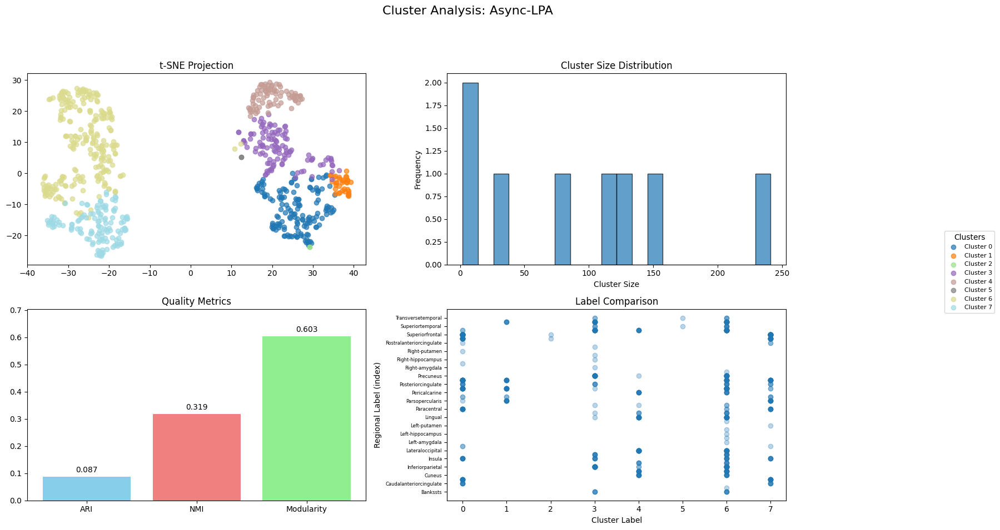


Analyzing LPA...
--- LPA Clustering Analysis ---
Number of clusters: 6
Cluster sizes: [248, 2, 124, 2, 265, 107]
ARI: 0.0502
NMI: 0.2187
Modularity: 0.5850
Coverage: 0.8813
Silhouette: -0.3196
--------------------------------------------------


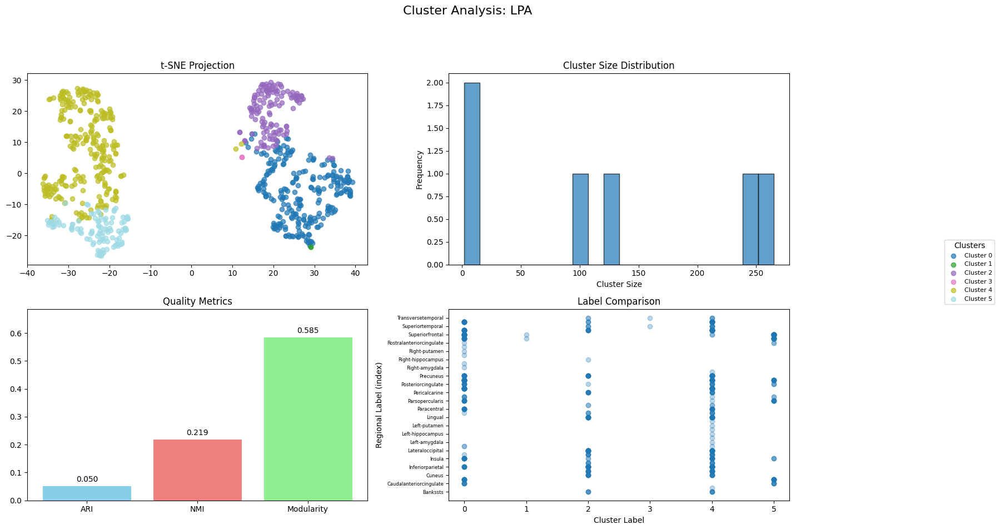


Analyzing MCL...
--- MCL Clustering Analysis ---
Number of clusters: 13
Cluster sizes: [285, 2, 8, 4, 2, 72, 2, 2, 353, 2, 8, 4, 4]
ARI: 0.0131
NMI: 0.1602
Modularity: 0.5283
Coverage: 0.9504
Silhouette: -0.3769
--------------------------------------------------


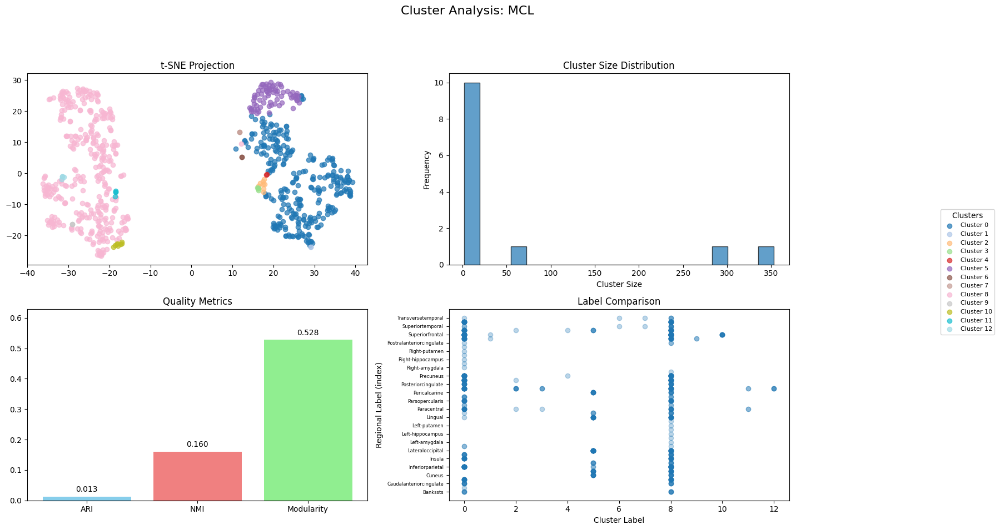


Analyzing Node2Vec...
--- Node2Vec Clustering Analysis ---
Number of clusters: 43
Cluster sizes: [78, 63, 62, 3, 2, 2, 2, 6, 2, 7, 2, 4, 4, 11, 4, 5, 3, 5, 5, 2, 91, 5, 64, 14, 43, 5, 8, 11, 27, 10, 8, 15, 12, 10, 29, 6, 10, 43, 6, 16, 9, 16, 18]
ARI: 0.1275
NMI: 0.4938
Modularity: 0.4755
Coverage: 0.5809
Silhouette: -0.4650
--------------------------------------------------


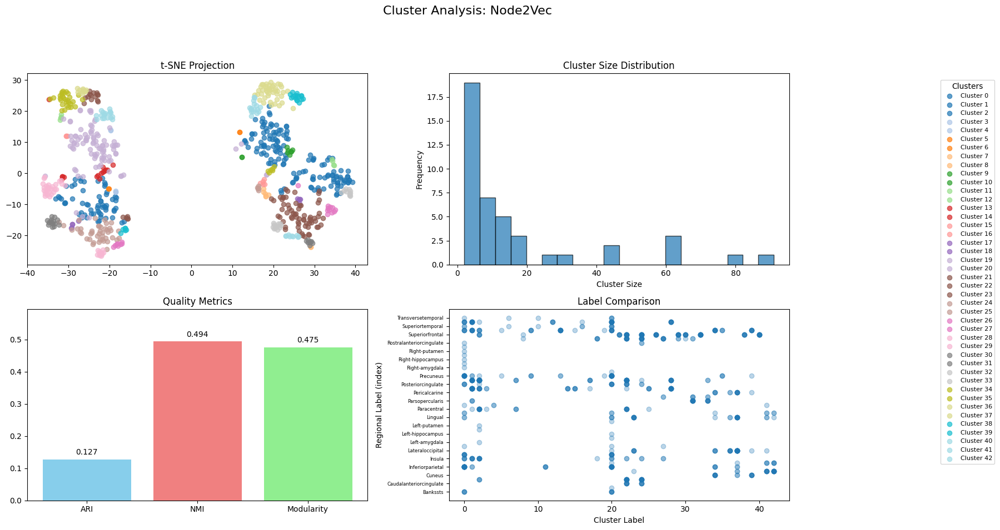

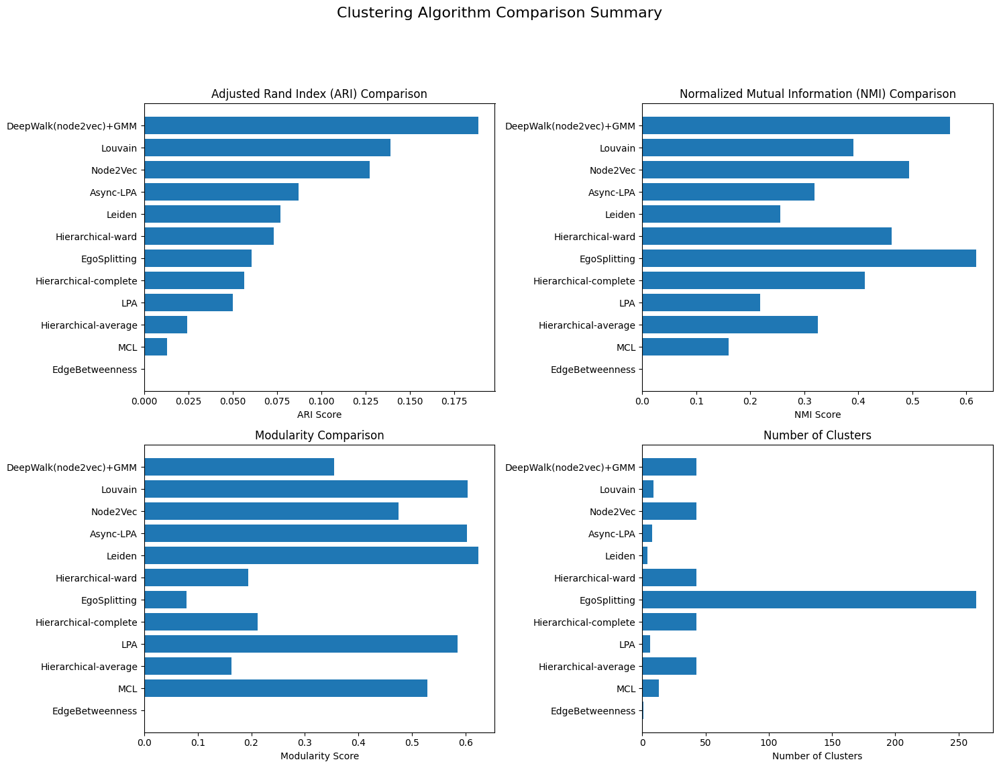

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set a nice global theme for colorful and clean plots
sns.set_theme(style="whitegrid", context="talk", font_scale=1.0)

def plot_cluster_analysis(G, labels, original_labels, emb_2d, method_name):
    try:
        eval_metrics = evaluate_clusters(G, labels, original_labels)
        labels_array = np.array(labels)
        cluster_sizes = [np.sum(labels_array == l) for l in np.unique(labels_array)]
        degrees = [d for n, d in G.degree()]

        print(f"--- {method_name} Clustering Analysis ---")
        print(f"Number of clusters: {len(np.unique(labels_array))}")
        print(f"Cluster sizes: {cluster_sizes}")
        print(f"ARI: {eval_metrics['ARI']:.4f}")
        print(f"NMI: {eval_metrics['NMI']:.4f}")
        print(f"Modularity: {eval_metrics['Modularity']:.4f}")
        print(f"Coverage: {eval_metrics['Coverage']:.4f}")
        print(f"Silhouette: {eval_metrics['Silhouette']:.4f}")
        print(f"Degree summary (min, max, mean): {min(degrees)}, {max(degrees)}, {np.mean(degrees):.2f}")
        print("-"*50)

        plt.figure(figsize=(20, 15))

        # 1. T-SNE embedding
        plt.subplot(2, 3, 1)
        unique_labels = list(set(labels))
        # Colorful palette with distinct colors (husl handles >20 colors better than tab20)
        colors = sns.color_palette("husl", len(unique_labels)) if len(unique_labels) > 20 else sns.color_palette("tab20", len(unique_labels))
        for i, label in enumerate(unique_labels):
            mask = labels_array == label
            plt.scatter(emb_2d[mask, 0], emb_2d[mask, 1],
                       color=colors[i], label=f'Cluster {label}', alpha=0.8, edgecolors='w', linewidth=0.5)
        plt.title("t-SNE Projection")
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

        # 2. Cluster size distribution
        plt.subplot(2, 3, 2)
        plt.hist(cluster_sizes, bins=20, alpha=0.8, edgecolor='black', color='mediumpurple')
        plt.title("Cluster Size Distribution")
        plt.xlabel("Cluster Size")
        plt.ylabel("Frequency")

        # 3. ARI/NMI comparison
        plt.subplot(2, 3, 3)
        metrics = ['ARI', 'NMI']
        values = [eval_metrics[m] for m in metrics]
        bars = plt.bar(metrics, values, color=sns.color_palette("Set2", 2), edgecolor='black')
        plt.title("Alignment Metrics")
        plt.ylim(0, 1)
        # Add value labels on bars
        for bar, value in zip(bars, values):
            plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                    f'{value:.3f}', ha='center', va='bottom')

        # 4. Original vs clustered (Colored by Cluster Label)
        plt.subplot(2, 3, 4)
        plt.scatter(labels, original_labels, alpha=0.6, c=labels_array, cmap='viridis', edgecolors='k', linewidth=0.2)
        plt.xlabel("Cluster Label")
        plt.ylabel("Regional Label")
        plt.title("Label Comparison")

        # 5. Degree distribution by cluster
        plt.subplot(2, 3, 5)
        data_to_plot = [[degrees[i] for i in range(len(labels)) if labels[i] == label]
                        for label in unique_labels]
        # patch_artist=True and facecolor makes the boxplot colorful
        box = plt.boxplot(data_to_plot, labels=unique_labels, patch_artist=True)
        for patch, color in zip(box['boxes'], colors):
            patch.set_facecolor(color)
            patch.set_alpha(0.7)
        plt.title("Degree Distribution by Cluster")
        plt.xlabel("Cluster")
        plt.ylabel("Degree")

        # 6. Modularity and Coverage
        plt.subplot(2, 3, 6)
        quality_metrics = ['Modularity', 'Coverage']
        quality_values = [eval_metrics['Modularity'], eval_metrics['Coverage']]
        bars = plt.bar(quality_metrics, quality_values, color=sns.color_palette("Set1", 2), edgecolor='black')
        plt.title("Quality Metrics")
        # Add value labels on bars
        for bar, value in zip(bars, quality_values):
            plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                    f'{value:.3f}', ha='center', va='bottom')

        plt.suptitle(f"Cluster Analysis: {method_name}", fontsize=20, fontweight='bold', color='#2a2a72')
        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"Error plotting {method_name}: {str(e)}")
        plt.figure(figsize=(10, 6))
        plt.text(0.5, 0.5, f"Error plotting {method_name}\n{str(e)}",
                ha='center', va='center', transform=plt.gca().transAxes, color='red')
        plt.title(f"Cluster Analysis: {method_name} - ERROR")
        plt.show()


def plot_cluster_analysis_simple(G, labels, original_labels, emb_2d, method_name):
    """Simplified version without seaborn dependencies but highly colorful"""
    try:
        eval_metrics = evaluate_clusters(G, labels, original_labels)
        labels_array = np.array(labels)
        cluster_sizes = [np.sum(labels_array == l) for l in np.unique(labels_array)]

        print(f"--- {method_name} Clustering Analysis ---")
        print(f"Number of clusters: {len(np.unique(labels_array))}")
        print(f"Cluster sizes: {cluster_sizes}")
        for metric in ['ARI', 'NMI', 'Modularity', 'Coverage', 'Silhouette']:
            print(f"{metric}: {eval_metrics[metric]:.4f}")
        print("-"*50)

        # ---- figure + axes ----
        fig, axes = plt.subplots(2, 2, figsize=(18, 10))
        fig.patch.set_facecolor('#f7f7fb') # Subtle background color

        # =========================================================
        # 1) t-SNE embedding
        # =========================================================
        unique_labels = list(set(labels))
        colors = sns.color_palette("husl", len(unique_labels)) if len(unique_labels) > 20 else sns.color_palette("tab20", len(unique_labels))
        for i, label in enumerate(unique_labels):
            mask = labels_array == label
            axes[0, 0].scatter(
                emb_2d[mask, 0],
                emb_2d[mask, 1],
                color=colors[i],
                label=f'Cluster {label}',
                alpha=0.8,
                edgecolors='w',
                linewidth=0.5
            )
        axes[0, 0].set_title("t-SNE Projection", color='#2a2a72', fontweight='bold')

        # =========================================================
        # 2) Cluster size distribution
        # =========================================================
        axes[0, 1].hist(cluster_sizes, bins=20, alpha=0.8, edgecolor='black', color='mediumseagreen')
        axes[0, 1].set_title("Cluster Size Distribution", color='#2a2a72', fontweight='bold')
        axes[0, 1].set_xlabel("Cluster Size")
        axes[0, 1].set_ylabel("Frequency")

        # =========================================================
        # 3) Metrics comparison
        # =========================================================
        metrics = ['ARI', 'NMI', 'Modularity']
        values = [eval_metrics[m] for m in metrics]
        bars = axes[1, 0].bar(metrics, values, color=sns.color_palette("Set2", 3), edgecolor='black')
        axes[1, 0].set_title("Quality Metrics", color='#2a2a72', fontweight='bold')
        axes[1, 0].set_ylim(0, max(values) + 0.1)
        for bar, value in zip(bars, values):
            axes[1, 0].text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.01,
                f'{value:.3f}',
                ha='center',
                va='bottom',
                fontweight='bold'
            )

        # =========================================================
        # 4) Label comparison (Colored by Cluster)
        # =========================================================
        regions, region_idx = np.unique(np.array(original_labels), return_inverse=True)

        # Apply viridis colormap to scatter points based on their cluster label
        scatter = axes[1, 1].scatter(labels, region_idx, alpha=0.6, c=labels_array, cmap='viridis', edgecolors='k', linewidth=0.3)
        axes[1, 1].set_xlabel("Cluster Label")
        axes[1, 1].set_ylabel("Regional Label (index)")
        axes[1, 1].set_title("Label Comparison", color='#2a2a72', fontweight='bold')

        # Show only a subset of region names as ticks
        max_ticks = 15
        step = max(1, len(regions) // max_ticks)
        tick_positions = np.arange(0, len(regions), step)
        axes[1, 1].set_yticks(tick_positions)
        axes[1, 1].set_yticklabels(regions[tick_positions], fontsize=8)

        # =========================================================
        # Legend OUTSIDE the subplots (right side)
        # =========================================================
        handles, legend_labels = axes[0, 0].get_legend_handles_labels()
        fig.legend(
            handles,
            legend_labels,
            loc="center right",
            bbox_to_anchor=(1.03, 0.5),
            title="Clusters",
            fontsize=9,
            title_fontsize=11
        )

        # Title + layout
        fig.suptitle(f"Cluster Analysis: {method_name}", fontsize=20, fontweight='bold', color='#1f1f39')
        fig.tight_layout(rect=[0.03, 0.03, 0.83, 0.93])

        plt.show()

    except Exception as e:
        print(f"Error in simple plot for {method_name}: {str(e)}")


def plot_summary_comparison(results_df):
    """Plot summary comparison of all methods with vibrant gradient colors"""
    try:
        fig, axes = plt.subplots(2, 2, figsize=(18, 12), constrained_layout=True)
        fig.patch.set_facecolor('#f7f7fb')

        # Sort by ARI for better visualization
        sorted_df = results_df.sort_values('ARI', ascending=True).reset_index(drop=True)
        n_methods = len(sorted_df)

        # 1. ARI comparison (Plasma gradient)
        colors_ari = sns.color_palette("plasma", n_methods)
        bars_ari = axes[0,0].barh(sorted_df['Algorithm'], sorted_df['ARI'], color=colors_ari, edgecolor='black', linewidth=0.5)
        axes[0,0].set_title('Adjusted Rand Index (ARI)', color='#2a2a72', fontweight='bold')
        axes[0,0].set_xlabel('ARI Score')

        # 2. NMI comparison (Viridis gradient)
        colors_nmi = sns.color_palette("viridis", n_methods)
        bars_nmi = axes[0,1].barh(sorted_df['Algorithm'], sorted_df['NMI'], color=colors_nmi, edgecolor='black', linewidth=0.5)
        axes[0,1].set_title('Normalized Mutual Information (NMI)', color='#2a2a72', fontweight='bold')
        axes[0,1].set_xlabel('NMI Score')

        # 3. Modularity comparison (Cividis gradient)
        colors_mod = sns.color_palette("cividis", n_methods)
        bars_mod = axes[1,0].barh(sorted_df['Algorithm'], sorted_df['Modularity'], color=colors_mod, edgecolor='black', linewidth=0.5)
        axes[1,0].set_title('Modularity', color='#2a2a72', fontweight='bold')
        axes[1,0].set_xlabel('Modularity Score')

        # 4. Number of clusters (Rocket/Magma gradient)
        colors_clusters = sns.color_palette("magma", n_methods)
        bars_clu = axes[1,1].barh(sorted_df['Algorithm'], sorted_df['Clusters'], color=colors_clusters, edgecolor='black', linewidth=0.5)
        axes[1,1].set_title('Number of Clusters', color='#2a2a72', fontweight='bold')
        axes[1,1].set_xlabel('Cluster Count')

        fig.suptitle('Clustering Algorithm Comparison Summary', fontsize=22, fontweight='bold', color='#1f1f39')

        plt.show()

    except Exception as e:
        print(f"Error creating summary plot: {str(e)}")


# Run the analysis
print("Generating cluster analysis plots...")

# Check if we have results to plot
if 'results_df' in locals() and not results_df.empty:
    top_methods = results_df.head(6)['Algorithm'].tolist()  # Plot top 6 methods

    for method in top_methods:
        try:
            matching_results = [res for res in cluster_results if res[0] == method]
            if matching_results:
                labels = matching_results[0][1]
                print(f"\nAnalyzing {method}...")
                # Use the simple version to avoid seaborn issues
                plot_cluster_analysis_simple(G_lcc, labels, original_labels, embeddings_2d, method)
            else:
                print(f"No results found for {method}")
        except Exception as e:
            print(f"Failed to analyze {method}: {str(e)}")
else:
    print("No results available for plotting")

# Create summary plot
if 'results_df' in locals() and not results_df.empty:
    plot_summary_comparison(results_df)

Consensus Clustering Analysis:

Consensus Clustering Metrics:
        ARI       NMI  Modularity  Coverage  Silhouette  Clusters
0  0.143741  0.417516    0.557575  0.680934   -0.402067        15
--- Consensus Clustering Analysis ---
Number of clusters: 15
Cluster sizes: [77, 112, 117, 69, 116, 35, 100, 10, 46, 9, 19, 7, 14, 15, 2]
ARI: 0.1437
NMI: 0.4175
Modularity: 0.5576
Coverage: 0.6809
Silhouette: -0.4021
Degree summary (min, max, mean): 1, 205, 30.11
--------------------------------------------------


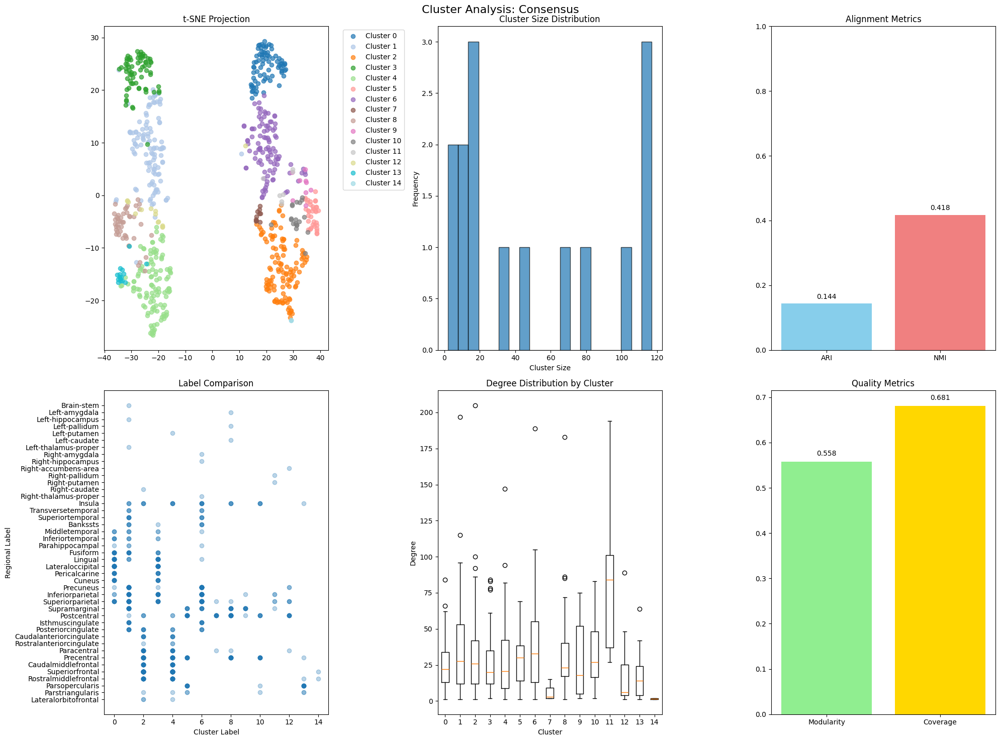

In [54]:
print("Consensus Clustering Analysis:")
from sklearn.cluster import KMeans
from scipy.stats import mode

# Create consensus matrix from top 3 methods
top_methods = results_df.head(3)['Algorithm'].tolist()
consensus_matrix = np.zeros((n_nodes, n_nodes))
top_labels = [res[1] for res in cluster_results if res[0] in top_methods]

for i in range(n_nodes):
    for j in range(n_nodes):
        consensus_matrix[i,j] = sum(1 for labels in top_labels if labels[i] == labels[j]) / len(top_labels)

consensus_labels = SpectralClustering(n_clusters=15, affinity='precomputed').fit_predict(consensus_matrix)

consensus_metrics = evaluate_clusters(G_lcc, consensus_labels, original_labels)
print("\nConsensus Clustering Metrics:")
print(pd.DataFrame([consensus_metrics]))

plot_cluster_analysis(G_lcc, consensus_labels, original_labels, embeddings_2d, "Consensus")

#### **Algorithm Comparison vs. Original Regional Labelling**

**Regional Misalignment:**  
Limited alignment with predefined regional labels persisted across all updated algorithms (ARI < 0.19). The embedding-based **DeepWalk(node2vec)+GMM** yielded the strongest regional correspondence (ARI = **0.1887**), whereas Louvain emerged as the top performer among purely structural approaches (ARI = **0.1390**). Conversely, Leiden—despite achieving the highest modularity—demonstrated weak regional alignment (ARI = **0.0770**). These findings suggest that connectivity patterns span multiple functional systems, failing to strictly adhere to predefined regional boundaries.

**Modularity-Region Trade-off:**  
An evident trade-off exists between maximizing modularity and preserving regional specificity. Although Leiden attained the highest modularity (**0.6235**), it generated only **4 broad clusters**, substantially oversimplifying the network. Louvain, by contrast, produced **9 clusters** alongside solid modularity (**0.6036**) and stronger regional alignment (ARI = **0.1390**), thereby striking a better balance between structural quality and regional relevance. While LPA and Async-LPA also achieved moderate-to-high modularity (**0.5850** and **0.6027**), these methods introduced instability and yielded very weak regional alignment (ARI ≤ **0.0871**).

**Embedding / Random-Walk Based Clustering:**
Node2Vec reasonably captured structural organization, as indicated by its high NMI (**0.4938**); however, its regional alignment remained modest (ARI = **0.1275**). A strongly negative silhouette score (**-0.4650**) implies that while Node2Vec embeddings reflect structural variation, they fail to form cohesive or internally consistent clusters. Notably, the **DeepWalk(node2vec)+GMM** approach secured the highest overall ARI (**0.1887**) and NMI (**0.5701**), albeit with heavily penalized modularity (**0.3548**) and a poor silhouette score (**-0.5545**).

**Stability Issues:**  
Meaningful partitions proved elusive for several algorithms. MCL suffered from strong fragmentation, generating **13 clusters** and achieving near-zero regional alignment (ARI = **0.0131**). Hierarchical methods (ward, complete, average) failed to capture the network's topology, resulting in low modularity (≤ **0.2113**) and poor regional alignment (ARI ≤ **0.0732**). Extreme over-fragmentation characterized EgoSplitting, which produced **264 clusters**, driving its ARI down to **0.0606** and its silhouette to a severely negative **-0.8696**. EdgeBetweenness collapsed entirely, yielding only a single cluster (ARI = **0.0000**). Throughout these tests, Louvain proved to be the most stable graph-based method, consistently generating **9** well-structured clusters.

**Summary of Embedding Methods:**  
Ultimately, a clear dichotomy emerges: purely structural algorithms prioritize modularity at the expense of regional alignment, whereas embedding methods (particularly DeepWalk+GMM) successfully capture regional heterogeneity (yielding the highest NMI and ARI) but sacrifice structural cohesion in the process, evidenced by negative silhouette scores and drastically reduced modularity.

#### **Direct Algorithm Comparisons**

1. **Leiden vs. Louvain:**  
   - **Leiden:** Produced the highest modularity (**0.6235**) but with only **4 clusters**, resulting in a network that is oversimplified and lacking regional granularity (ARI = **0.0770**).
   - **Louvain:** Delivered a more balanced result by forming **9 clusters** with better regional alignment (ARI = **0.1390**) and strong modularity (**0.6036**). In updated results, Louvain clearly offers a more region-sensitive community structure compared to Leiden.

2. **Hierarchical Methods:**  
   - When comparing hierarchical clustering methods, Ward linkage outperformed both complete and average linkages with an ARI of **0.0732** (Modularity: **0.1939**) as opposed to **0.0566** (Modularity: **0.2113**) and **0.0245** (Modularity: **0.1626**) respectively. It is important to note that all hierarchical methods in this analysis showed rather poor modularity (all below **0.22**), which further highlights their limitations for this kind of regional analysis.

3. **Label Propagation–Based Methods:**  
   - **LPA:** Moderately high modularity (**0.5850**) but poor alignment with regional labels (ARI = **0.0502**), yielding **6 clusters** and unstable outputs including several 2-node micro-clusters.
   - **Async LPA:** Showed slightly better regional alignment (ARI = **0.0871**) and higher modularity (**0.6027**), producing **8 clusters**. Despite this, the persistence of tiny groups reinforces that LP-based approaches remain unreliable for this dataset.

4. **Embedding Approaches:**
   - **Node2Vec:** Exhibited strong structural detection (NMI = **0.4938**), but only moderate regional alignment (ARI = **0.1275**). Its silhouette score (**-0.4650**) showed that the resulting clusters were highly incoherent, despite capturing structural diversity across **43 clusters**.
   - **DeepWalk(node2vec)+GMM:** Achieved the strongest overall regional alignment (ARI = **0.1887**) and structural overlap (NMI = **0.5701**), also generating **43 clusters**. However, this came at the cost of heavily penalized modularity (**0.3548**) and a poor silhouette score (**-0.5545**).

5. **Stability and Efficiency:**  
   - **Louvain:** The most stable algorithm, consistently producing **9** reproducible clusters without micro-fragmentation.
   - **MCL:** The least stable among structural methods, yielding **13** fragmented clusters and negligible regional alignment (ARI = **0.0131**).
   - **Edge Cases:** **EgoSplitting** severely over-fragmented the network into **264 clusters**, achieving an ARI of **0.0606**. **EdgeBetweenness** collapsed entirely, producing only **1 cluster** and an ARI of **0.0000**.
   - **Efficiency:** Leiden and Louvain remained the fastest methods, while Node2Vec and DeepWalk required more computational effort to produce **43 clusters** with a wide range of sizes.

#### **Conclusion**

In conclusion, the analysis reveals a persistent disconnect between the brain network’s structural organisation and predefined anatomical labels. High-modularity algorithms prioritise topological cohesion over regional specificity. Leiden achieved the highest modularity (**0.6235**) but over-simplified the network into only four broad clusters (ARI = **0.0770**). Louvain offered a more balanced structural approach, generating nine clusters with strong modularity (**0.6036**) and the best regional alignment among structural methods (ARI = **0.1390**). Meanwhile, label-propagation methods proved unstable, yielding fragmented micro-clusters and weak regional alignment (ARI ≤ **0.0871**).

Embedding-based clustering captured regional heterogeneity more effectively but sacrificed structural cohesion. **DeepWalk(node2vec)+GMM** achieved the highest overall regional correspondence (ARI = **0.1887**, NMI = **0.5701**) and Node2Vec showed strong structural detection (NMI = **0.4938**), yet both produced negative silhouette scores, indicating internally incoherent clusters. Other methods failed entirely: MCL fragmented into 13 clusters (ARI = **0.0131**), EgoSplitting heavily over-fragmented the network into 264 clusters, and EdgeBetweenness collapsed into a single cluster (ARI = **0.0000**).

The t-SNE projections and label comparison matrices provide clear visual validation of the metric trade-offs. Leiden's high modularity (0.6235) is revealed to be an artifact of geometric partitioning: its t-SNE plot shows four perfectly balanced quadrants, and its label comparison shows every anatomical region split evenly across all four clusters. Conversely, Node2Vec's negative silhouette score (-0.4650) is visually confirmed by its highly overlapping, fragmented t-SNE space, where the 43 clusters bleed into one another. Louvain emerges as the most biologically plausible structural method, displaying organic, non-uniform cluster shapes and a natural size distribution that avoids the micro-cluster fragmentation seen in MCL and LPA.

Overall, these findings highlight a fundamental trade-off between structural modularity and regional specificity. No single algorithm fully captures the network’s multidimensional structure, emphasising the importance of multi-algorithm integration when analysing complex brain connectivity data.

## Problem 3. Assortativity (15 points)

- Рассмотрите:
  - Коннектом целиком
  - Различные области, найденные с помощью автоматической разметки, по отдельности
- Посчитайте для них ассортативность, постройте необходимые графики
- Проанализируйте результаты
- Consider:
  - Connect as a whole
  - Various areas found using automatic labeing individually
- Calculate the assortativity for them, plot the necessary graphs
- Analyze the results

In [60]:
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
import numpy as np

In [61]:
nx.set_node_attributes(G_lcc, {node: label for node, label in zip(G_lcc.nodes(), original_labels)}, 'regional_label')

degree_assort_global = nx.degree_assortativity_coefficient(G_lcc)
regional_assort_global = nx.attribute_assortativity_coefficient(G_lcc, 'regional_label')

print("=== GLOBAL ASSORTATIVITY ===")
print(f"Degree assortativity: {degree_assort_global:.3f} (disassortative)")
print(f"Regional assortativity: {regional_assort_global:.3f} (assortative)")

=== GLOBAL ASSORTATIVITY ===
Degree assortativity: -0.024 (disassortative)
Regional assortativity: 0.186 (assortative)


Available methods in cluster_results:
  - Louvain
  - Leiden
  - DeepWalk(node2vec)+GMM
  - Node2Vec
  - Hierarchical-ward
  - Hierarchical-complete
  - Hierarchical-average
  - Async-LPA
  - MCL
  - LPA
  - EdgeBetweenness
  - EgoSplitting

Methods that will be analyzed: ['Louvain', 'Leiden', 'Hierarchical-ward', 'Hierarchical-complete', 'Hierarchical-average', 'Async-LPA', 'MCL', 'EdgeBetweenness', 'EgoSplitting']

=== LOUVAIN COMMUNITY VALUES ===
Community    Size   DegreeAssort    RegionalAssort 
0            119    -0.070782       0.195649       
1            63     -0.152529       0.116084       
6            10     -0.282243       -0.131313      
4            103    -0.186381       0.084393       
7            81     -0.068220       0.068828       
3            126    -0.089440       0.112270       
8            121    -0.075595       0.150519       
2            56     -0.032302       0.177938       
5            69     -0.101786       0.097996       

Summary - Avg Degree Asso

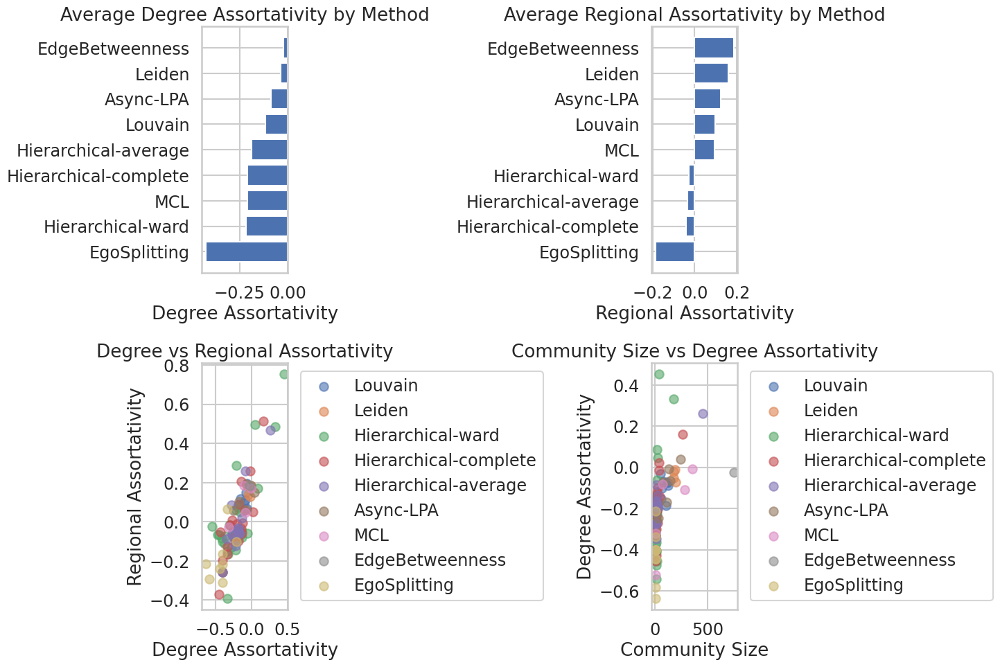


DETAILED RESULTS:
           Method  Community  Size  DegreeAssort  RegionalAssort
0         Louvain          0   119       -0.0708          0.1956
1         Louvain          1    63       -0.1525          0.1161
2         Louvain          6    10       -0.2822         -0.1313
3         Louvain          4   103       -0.1864          0.0844
4         Louvain          7    81       -0.0682          0.0688
..            ...        ...   ...           ...             ...
127  EgoSplitting        604     6           NaN         -0.2000
128  EgoSplitting        640     6       -0.4000             NaN
129  EgoSplitting        578     6       -0.6364         -0.2135
130  EgoSplitting        589     6       -0.4000             NaN
131  EgoSplitting        659     6       -0.4000         -0.2174

[132 rows x 5 columns]


In [62]:
# First, let's see what methods are actually available in cluster_results
available_methods = [res[0] for res in cluster_results]
print("Available methods in cluster_results:")
for method in available_methods:
    print(f"  - {method}")

# Create a filtered list of methods that actually exist
selected_methods = [
    "Louvain",
    "Leiden",
    "Hierarchical-ward",
    "Hierarchical-complete",
    "Hierarchical-average",
    "GraphWave",
    "Async-LPA",
    "MCL",
    "EdgeBetweenness",
    "EgoSplitting"
]

# Filter to only include methods that exist in cluster_results
existing_methods = [method for method in selected_methods if method in available_methods]
print(f"\nMethods that will be analyzed: {existing_methods}")

communities = {}
assort_results = []

for method in existing_methods:
    try:
        # Get labels for this method
        labels = [res[1] for res in cluster_results if res[0] == method][0]

        # Create communities dictionary
        comms = defaultdict(list)
        node_list = list(G_lcc.nodes())
        for idx, label in enumerate(labels):
            node = node_list[idx]
            comms[label].append(node)
        communities[method] = comms

        print(f"\n=== {method.upper()} COMMUNITY VALUES ===")
        print(f"{'Community':<12} {'Size':<6} {'DegreeAssort':<15} {'RegionalAssort':<15}")

        # Calculate assortativity for each community with sufficient size
        for label, nodes in comms.items():
            if len(nodes) > 5:  # Reduced threshold to include more communities
                try:
                    subgraph = G_lcc.subgraph(nodes)

                    # Check if subgraph has enough edges for assortativity calculation
                    if subgraph.number_of_edges() > 5:
                        degree_assort = nx.degree_assortativity_coefficient(subgraph)

                        # Check if 'regional_label' attribute exists
                        if 'regional_label' in list(G_lcc.nodes(data=True))[0][1]:
                            regional_assort = nx.attribute_assortativity_coefficient(subgraph, 'regional_label')
                        else:
                            # If regional_label doesn't exist, use original_labels
                            # Create a temporary attribute
                            temp_attrs = {node: original_labels[idx] for idx, node in enumerate(G_lcc.nodes())}
                            nx.set_node_attributes(subgraph, temp_attrs, 'temp_region')
                            regional_assort = nx.attribute_assortativity_coefficient(subgraph, 'temp_region')

                        print(f"{label:<12} {len(subgraph):<6} {degree_assort:<15.6f} {regional_assort:<15.6f}")

                        assort_results.append({
                            'Method': method,
                            'Community': label,
                            'Size': len(subgraph),
                            'DegreeAssort': degree_assort,
                            'RegionalAssort': regional_assort
                        })
                    else:
                        print(f"{label:<12} {len(subgraph):<6} {'N/A':<15} {'N/A':<15}")
                except Exception as e:
                    print(f"{label:<12} {len(nodes):<6} {'Error':<15} {'Error':<15}")
                    # print(f"  Error details: {str(e)}")  # Uncomment for debugging

        # Print summary statistics
        valid_results = [r for r in assort_results if r['Method'] == method and not np.isnan(r['DegreeAssort'])]
        if valid_results:
            avg_degree_assort = np.mean([r['DegreeAssort'] for r in valid_results])
            avg_regional_assort = np.mean([r['RegionalAssort'] for r in valid_results])
            print(f"\nSummary - Avg Degree Assort: {avg_degree_assort:.4f}, Avg Regional Assort: {avg_regional_assort:.4f}")

    except Exception as e:
        print(f"Error processing {method}: {str(e)}")
        continue

# Create DataFrame and display results
if assort_results:
    df_assort = pd.DataFrame(assort_results)

    # Display summary by method
    print("\n" + "="*80)
    print("SUMMARY BY METHOD:")
    print("="*80)

    summary_stats = df_assort.groupby('Method').agg({
        'DegreeAssort': ['mean', 'std', 'count'],
        'RegionalAssort': ['mean', 'std']
    }).round(4)

    print(summary_stats)

    # Create visualization
    plt.figure(figsize=(15, 10))

    # 1. Degree Assortativity by Method
    plt.subplot(2, 2, 1)
    method_means = df_assort.groupby('Method')['DegreeAssort'].mean().sort_values()
    plt.barh(range(len(method_means)), method_means.values)
    plt.yticks(range(len(method_means)), method_means.index)
    plt.title('Average Degree Assortativity by Method')
    plt.xlabel('Degree Assortativity')

    # 2. Regional Assortativity by Method
    plt.subplot(2, 2, 2)
    method_means_reg = df_assort.groupby('Method')['RegionalAssort'].mean().sort_values()
    plt.barh(range(len(method_means_reg)), method_means_reg.values)
    plt.yticks(range(len(method_means_reg)), method_means_reg.index)
    plt.title('Average Regional Assortativity by Method')
    plt.xlabel('Regional Assortativity')

    # 3. Scatter plot: Degree vs Regional Assortativity
    plt.subplot(2, 2, 3)
    for method in df_assort['Method'].unique():
        method_data = df_assort[df_assort['Method'] == method]
        plt.scatter(method_data['DegreeAssort'], method_data['RegionalAssort'],
                   label=method, alpha=0.6)
    plt.xlabel('Degree Assortativity')
    plt.ylabel('Regional Assortativity')
    plt.title('Degree vs Regional Assortativity')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

    # 4. Community size distribution
    plt.subplot(2, 2, 4)
    for method in df_assort['Method'].unique():
        method_data = df_assort[df_assort['Method'] == method]
        plt.scatter(method_data['Size'], method_data['DegreeAssort'],
                   label=method, alpha=0.6)
    plt.xlabel('Community Size')
    plt.ylabel('Degree Assortativity')
    plt.title('Community Size vs Degree Assortativity')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

    plt.tight_layout()
    plt.show()

    # Display detailed results
    print("\n" + "="*80)
    print("DETAILED RESULTS:")
    print("="*80)
    print(df_assort.round(4))

else:
    print("No assortativity results to display.")

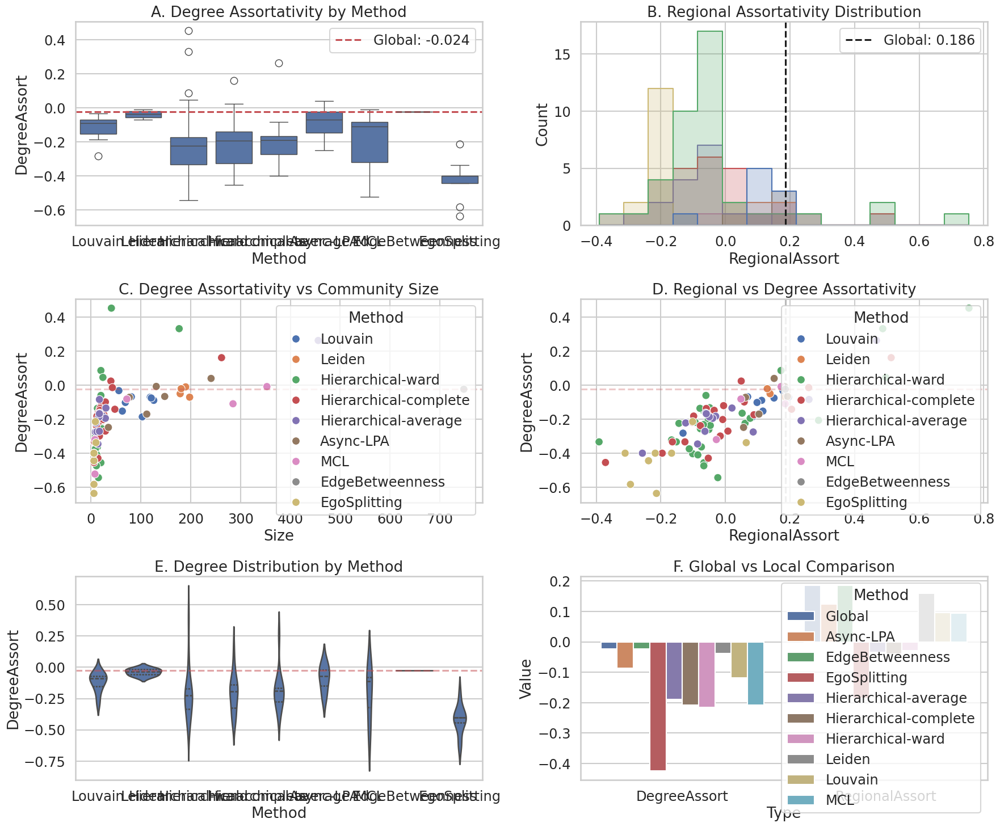

In [63]:
plt.figure(figsize=(18, 15))

# Plot 1: Degree Assortativity by Method (Boxplot)
plt.subplot(3, 2, 1)
sns.boxplot(x='Method', y='DegreeAssort', data=df_assort)
plt.axhline(degree_assort_global, color='r', linestyle='--', label=f'Global: {degree_assort_global:.3f}')
plt.title("A. Degree Assortativity by Method")
plt.legend()

# Plot 2: Regional Assortativity Distribution (Histogram)
plt.subplot(3, 2, 2)
sns.histplot(data=df_assort, x='RegionalAssort', hue='Method', element='step', bins=15)
plt.axvline(regional_assort_global, color='k', linestyle='--', label=f'Global: {regional_assort_global:.3f}')
plt.title("B. Regional Assortativity Distribution")
plt.legend()

# Plot 3: Degree vs. Community Size (Scatter)
plt.subplot(3, 2, 3)
sns.scatterplot(x='Size', y='DegreeAssort', hue='Method', data=df_assort, s=100)
plt.axhline(degree_assort_global, color='r', linestyle='--', alpha=0.3)
plt.title("C. Degree Assortativity vs Community Size")

# Plot 4: Regional vs. Degree Assortativity (Scatter)
plt.subplot(3, 2, 4)
sns.scatterplot(x='RegionalAssort', y='DegreeAssort', hue='Method', data=df_assort, s=100)
plt.axvline(regional_assort_global, color='k', linestyle='--', alpha=0.3)
plt.axhline(degree_assort_global, color='r', linestyle='--', alpha=0.3)
plt.title("D. Regional vs Degree Assortativity")

# Plot 5: Degree Distribution (Violin)
plt.subplot(3, 2, 5)
sns.violinplot(x='Method', y='DegreeAssort', data=df_assort, inner="quartile")
plt.axhline(degree_assort_global, color='r', linestyle='--', alpha=0.5)
plt.title("E. Degree Distribution by Method")

# Plot 6: Global vs Local Comparison (Bar)
plt.subplot(3, 2, 6)
comparison = pd.concat([
    pd.DataFrame({
        'Method': ['Global'],
        'DegreeAssort': [degree_assort_global],
        'RegionalAssort': [regional_assort_global]
    }),
    df_assort.groupby('Method')[['DegreeAssort', 'RegionalAssort']].mean().reset_index()
])
melted = comparison.melt(id_vars='Method', var_name='Type', value_name='Value')
sns.barplot(x='Type', y='Value', hue='Method', data=melted)
plt.title("F. Global vs Local Comparison")

plt.tight_layout()
plt.show()

In [64]:
print("\n=== METHOD-WISE SUMMARY STATISTICS ===")
print(df_assort.groupby('Method').agg({
    'DegreeAssort': ['count', 'mean', 'std', 'min', 'median', 'max'],
    'RegionalAssort': ['mean', 'std', 'min', 'max'],
    'Size': ['mean', 'sum']
}))


=== METHOD-WISE SUMMARY STATISTICS ===
                      DegreeAssort                                          \
                             count      mean       std       min    median   
Method                                                                       
Async-LPA                        6 -0.087372  0.105768 -0.248242 -0.069019   
EdgeBetweenness                  1 -0.023609       NaN -0.023609 -0.023609   
EgoSplitting                    11 -0.423714  0.112063 -0.636364 -0.400000   
Hierarchical-average            14 -0.188532  0.154621 -0.400000 -0.190678   
Hierarchical-complete           22 -0.207672  0.153199 -0.454545 -0.191983   
Hierarchical-ward               34 -0.215458  0.205142 -0.543717 -0.224429   
Leiden                           4 -0.038002  0.027636 -0.070706 -0.035600   
Louvain                          9 -0.117697  0.077275 -0.282243 -0.089440   
MCL                              5 -0.208357  0.210405 -0.522538 -0.109454   

                       


### **Analysis of Assortativity in the Human Connectome**  
#### **Global Assortativity**  
An examination of the network at the global level uncovers two primary wiring behaviors within the connectome.

Initially, the network demonstrates a **slight degree disassortativity (-0.024)**. This indicates that high-degree hubs preferentially link to nodes with fewer connections instead of clustering with other hubs, a configuration that facilitates the efficient broadcast of information across different modules.

Furthermore, the **regional assortativity exhibits a moderately positive value (0.186)**. This finding confirms that brain areas sharing similar functional identities such as sensorimotor, attention, and visual regions—have a strong tendency to interconnect. Consequently, this implies that regional specialization persists as a fundamental organizing principle, even in the presence of topological mixing.

#### **Local Assortativity Across Methods**  
To investigate the variations in local wiring among different communities, we assessed the outcomes of automatic labeling generated by a variety of algorithms. While the data highlights consistent overarching trends, it also reveals significant disparities based on whether a given method prioritizes hierarchical organization, topology, or local structural features *(refer to the grouped bar charts and boxplots for the visual distribution)*.

**1. Topology-Driven Methods (Leiden, Louvain, Async-LPA):**
Rather than relying on functional or anatomical data, these algorithms are driven primarily by underlying connectivity patterns. Each of the three methods demonstrates **local degree disassortativity**, indicating a propensity to blend nodes of varying degrees within individual communities.

- **Leiden**
  - **Mean degree assortativity:** -0.0380
  - **Mean regional assortativity:** 0.1594
  - The Leiden algorithm generates four substantial and evenly sized communities (ranging from 179 to 198 nodes). Every cluster exhibits regional assortativity between 0.1296 and 0.1859, suggesting that clusters defined purely by topology still maintain robust functional coherence.

- **Louvain**
  - **Mean degree assortativity:** -0.1177
  - **Mean regional assortativity:** 0.0969
  - Communities identified by Louvain maintain a steady state of disassortativity, reaching as low as -0.2822 within the smallest cluster. Regional assortativity fluctuates considerably between -0.1313 and 0.1956, illustrating a blend of moderately specialized groups and connector-type communities.

- **Async-LPA**
  - **Mean degree assortativity:** -0.0874
  - **Mean regional assortativity:** 0.1249
  - By partitioning the network into six clusters of medium to large sizes (35 to 241 nodes), Async-LPA preserves a moderate level of regional coherence, highlighted by one community that achieves a **RegionalAssort of 0.1923**.

**Summary:** In summary, while topology-based methods are highly effective at identifying connector-dense communities, they differ in their capacity to maintain regional structures. Leiden demonstrates the strongest alignment with regional boundaries, whereas Louvain is superior at capturing the network's structural diversity.

**2. Hierarchical Methods (Ward, Complete, Average)**
The application of hierarchical clustering results in substantial variability, often producing numerous small and unstable communities. As corroborated by the scatter plots, these techniques are exceedingly sensitive to minor local network features.

**Ward Linkage**
  - **Mean degree assortativity:** -0.2155
  - **Mean regional assortativity:** -0.0279
  - The values span a wide spectrum, ranging from strongly disassortative (DegreeAssort = -0.5437) to highly assortative (DegreeAssort = +0.4528, RegionalAssort = **0.7541**). This pronounced variance points to a lack of structural consistency.

**Complete Linkage**
  - **Mean degree assortativity:** -0.2077
  - **Mean regional assortativity:** -0.0408
  - The resulting communities feature a combination of large, regionally cohesive groups (achieving a RegionalAssort = **0.5133**) alongside numerous smaller clusters that exhibit weak regional alignment.

**Average Linkage**
  - **Mean degree assortativity:** -0.1885
  - **Mean regional assortativity:** -0.0344
  - This method yields a single, massive community comprising 456 nodes with a RegionalAssort = **0.4676**, while simultaneously generating multiple small, disassortative clusters.

**Summary:** To summarize, hierarchical methods are characterized by significant variance and high instability. Although they can occasionally isolate highly specialized regional modules, their general performance is erratic and heavily influenced by the size of the clusters.

**3. Markov Clustering (MCL)**
The MCL algorithm produces a combination of very small and large communities:
  - **Mean degree assortativity:** -0.2084
  - **Mean regional assortativity:** 0.0944
While smaller clusters (e.g., 8 nodes) yield negative or noisy metrics, larger communities (such as one with 353 nodes) display a moderate regional assortativity (**0.1723**). Consequently, MCL successfully identifies regional organization at the macro level but struggles with granular stability.

**4. Edge Betweenness**
By partitioning the network into a single, massive community of 748 nodes, the Edge Betweenness method yields the following metrics:
  - **Degree assortativity:** -0.0236
  - **Regional assortativity:** 0.1856
These figures essentially mirror the global assortativity values. Ultimately, this approach failed entirely to delineate any meaningful local community structure within the dataset.

**5. EgoSplitting**
Because EgoSplitting creates exceedingly small communities (primarily consisting of 6 nodes), it produces:
  - **Mean degree assortativity:** -0.4237
  - **Mean regional assortativity:** -0.1861
As depicted by the lower outliers in the boxplots, the severe fragmentation and unstable local architecture are evidenced by the negative regional values and extreme disassortativity. Therefore, this technique is unsuitable for generating reliable communities for assortativity analysis.

#### **Key Trends Across Methods**
**1. Degree Disassortativity is Universal Locally**
The majority of communities identified by successful algorithms exhibit **negative degree assortativity**. This finding corroborates the existence of connector hubs that bridge diverse regions, thereby averting the creation of isolated, hub-exclusive clusters.

**2. Regional Assortativity Depends Strongly on Community Size**
The *Community Size vs. Assortativity* scatter plots illustrate that:
  - Larger communities, such as those generated by Async-LPA, Louvain, and Leiden, demonstrate **positive regional assortativity** ranging from 0.10 to 0.19.
  - Conversely, smaller hierarchical clusters frequently exhibit **unstable or negative** regional assortativity.
This indicates that functional grouping primarily manifests at larger scales, whereas minuscule clusters lack the structural regularity necessary to reflect functional boundaries.

**3. Method Choice Strongly Shapes Interpretation**
  - **Leiden:** Optimal for achieving balanced groupings that align well with regional boundaries.
  - **Louvain:** Ideal for highlighting structural variability and defining clear hub–periphery dynamics.
  - **Hierarchical (Ward/Complete/Average):** Prone to extreme variance, high instability, and strong dependence on cluster size.
  - **MCL:** Offers moderate reliability, though it remains vulnerable to the influence of small clusters.
  - **EgoSplitting & EdgeBetweenness:** Unsuitable for this analysis due to complete structural collapse or excessive fragmentation.

#### **Biological Interpretation**
The overarching global paradigm—characterized by a **disassortative degree structure combined with regionally assortative organization**—is mirrored at the local level:

  - Communities exhibiting **disassortativity** (such as those identified by Ward at -0.5437 or Louvain at -0.2822) are likely indicative of **cross-system connector circuits**. These resemble prefrontal or thalamic hub networks that integrate cognitive and sensory systems.
  - Conversely, communities with high **regional assortativity** (such as specific Ward clusters reaching 0.7541 or Leiden at 0.1859) represent **specialized functional modules**, including attention or visual subnetworks.

Ultimately, the brain achieves a critical balance between **specialized regional clustering and hub-driven integration**, a hallmark of an efficient and highly flexible neural architecture.

#### **Conclusion**
The findings validate that the human connectome operates under a dual organizational framework:
**1. A slight global degree disassortativity** (-0.024) guarantees that hubs establish links across distinct systems, thereby facilitating rapid information transfer.
**2. A moderate level of regional assortativity** (0.186) underscores the presence of functionally cohesive modules.

At the local scale, the derived community structure fluctuates significantly depending on the chosen algorithm. While topology-centric methods (Leiden, Louvain, Async-LPA) successfully extract coherent, regionally aligned communities, ego-based and hierarchical approaches tend to produce excessively fragmented or unstable groupings. Furthermore, larger communities consistently demonstrate robust regional alignment, whereas smaller clusters primarily capture connector or peripheral roles.

In conclusion, the connectome concurrently prioritizes **cross-regional integration and functional specialization**. However, the specific algorithmic method chosen plays a critical role in determining how effectively these underlying patterns are exposed.

## Problem 4. Transcranial magnetic stimulation (30 points)

__[Transcranial magnetic stimulation (TMS)](https://en.wikipedia.org/wiki/Transcranial_magnetic_stimulation)__ - a method that allows noninvasively stimulating the cerebral cortex. It is used for the rehabilitation of patients (for example, with motor disorders), and for the treatment of various diseases: Parkinson's disease, epilepsy, depression, schizophrenia, and others.

We would like to suggest that you conduct a TMS on your "patient". For this, you will need:

- "Weigh" the edges of the graph. For example, using some metric that decreases with increasing distance between vertices.

- Apply TMS to different areas of the brain. See how far the signal will spread, which areas it will affect, and what functions these areas are responsible for.

  Various methods can be used to implement signal propagation: `message passing', `random walk', `heat diffusion' and others.

  Try different methods (two or more), compare the results.

---

To determine which areas of the brain should be targeted with TMS, you can refer to scientific articles. For example:

__[Evidence-based guidelines on the therapeutic use of repetitive transcranial magnetic stimulation (rTMS)](https://www.sciencedirect.com/science/article/pii/S1388245719312799?via%3Dihub)__.

This article contains many studies that stimulated various areas of the brain using TMS. It also describes the symptoms of patients and the results of TMS use.

---

For example, in the picture below you can see:

- The patient's symptom is a motor disorder of the hand as a result of stroke.

- The area of application of TMS is the M1 zone. You can use a __[map of brain regions](https://atlas.brain-map.org/atlas?atlas=265297126)__ to orient yourself in the areas of a brain.

- The result of the therapy is an improvement in the patient's motor functions.

![lab_1_example.png](attachment:lab_1_example.png)

---

Good luck!

In [65]:
import numpy as np
import networkx as nx
from scipy.sparse import csgraph, csr_matrix
from scipy.sparse.linalg import expm
from collections import defaultdict
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from sklearn.preprocessing import MinMaxScaler

for u, v in G_lcc.edges():
    pos_u = (G_lcc.nodes[u]['dn_position_x'], G_lcc.nodes[u]['dn_position_y'], G_lcc.nodes[u]['dn_position_z'])
    pos_v = (G_lcc.nodes[v]['dn_position_x'], G_lcc.nodes[v]['dn_position_y'], G_lcc.nodes[v]['dn_position_z'])
    distance = np.linalg.norm(np.array(pos_u) - np.array(pos_v))
    G_lcc[u][v]['weight'] = 1 / (distance + 1e-5)

weights = nx.get_edge_attributes(G_lcc, 'weight').values()
scaler = MinMaxScaler()
normalized_weights = scaler.fit_transform(np.array(list(weights)).reshape(-1, 1)).flatten()
for i, (u, v) in enumerate(G_lcc.edges()):
    G_lcc[u][v]['weight'] = normalized_weights[i]

In [66]:
def get_target_nodes(G, region_name, hemisphere=None):
    target_nodes = []
    if isinstance(region_name, list):
        for rn in region_name:
            for node, data in G.nodes(data=True):
                name_match = canonize_key(data.get('dn_name', '')) == canonize_key(rn)
                hemi_match = (hemisphere is None) or (canonize_key(data.get('dn_hemisphere', '')) == canonize_key(hemisphere))
                if name_match and hemi_match:
                    target_nodes.append(node)
    else:
        for node, data in G.nodes(data=True):
            name_match = canonize_key(data.get('dn_name', '')) == canonize_key(region_name)
            hemi_match = (hemisphere is None) or (canonize_key(data.get('dn_hemisphere', '')) == canonize_key(hemisphere))
            if name_match and hemi_match:
                target_nodes.append(node)
    return target_nodes

TARGETS = {
    'stroke_motor': {
        'region_name': 'Precentral',
        'hemisphere': 'Left'
    },
    'depression': {
        'region_name': 'Caudalmiddlefrontal',
        'hemisphere': 'Left'
    },
    'parkinsons': {
        'region_name': ['Precentral', 'Superiorfrontal'],
        'hemisphere': 'Left'
    },
    'tinnitus': {
        'region_name': 'Superiortemporal',
        'hemisphere': 'Right'
    },
    'schizophrenia': {
        'region_name': ['Caudalmiddlefrontal', 'Superiortemporal'],
        'hemisphere': 'Left'
    },
    'ptsd': {
        'region_name': 'Caudalmiddlefrontal',
        'hemisphere': 'Left'
    },
    'eating_disorder': {
        'region_name': 'Lateralorbitofrontal',
        'hemisphere': 'Left'
    },
    'aphasia': {
        'region_name': ['Parsopercularis', 'Superiortemporal'],
        'hemisphere': 'Left'
    }
}

In [67]:
def heat_diffusion(G, target_nodes, time=0.5):
    nodes = list(G.nodes())
    node_idx = {n: i for i, n in enumerate(nodes)}

    adj = nx.adjacency_matrix(G, weight='weight').astype(float)
    laplacian = csgraph.laplacian(adj, normed=False)

    heat = np.zeros(len(nodes))
    for node in target_nodes:
        heat[node_idx[node]] = 1.0

    diffused = expm(-laplacian * time).dot(heat)

    diffused = diffused / diffused.max()
    return {node: diffused[node_idx[node]] for node in nodes}

In [68]:
def random_walk(G, target_nodes, steps=1000, walk_length=10, restart_prob=0.15):
    activation = {node: 0 for node in G.nodes()}

    for _ in range(steps):
        current = np.random.choice(target_nodes)
        for _ in range(walk_length):
            activation[current] += 1
            if np.random.rand() < restart_prob:
                current = np.random.choice(target_nodes)
            else:
                neighbors = list(G.neighbors(current))
                weights = [G[current][n]['weight'] for n in neighbors]
                probs = np.array(weights) / sum(weights)
                current = np.random.choice(neighbors, p=probs)

    max_act = max(activation.values())
    return {k: v/max_act for k, v in activation.items()}

In [69]:
def message_passing(G, target_nodes, infection_rate=0.7, recovery_rate=0.2, iterations=5):
    activation = {node: 0 for node in G.nodes()}
    state = {node: 'S' for node in G.nodes()}

    for node in target_nodes:
        state[node] = 'I'
        activation[node] = 1

    for _ in range(iterations):
        new_infected = []
        for node in G.nodes():
            if state[node] == 'I':
                for neighbor in G.neighbors(node):
                    if state[neighbor] == 'S' and np.random.rand() < infection_rate * G[node][neighbor]['weight']:
                        new_infected.append(neighbor)
                if np.random.rand() < recovery_rate:
                    state[node] = 'R'

        for node in new_infected:
            state[node] = 'I'
            activation[node] += 1

    max_act = max(activation.values())
    return {k: v/max_act for k, v in activation.items()}

In [70]:
def betweenness_propagation(G, target_nodes, threshold=0.01):
    betweenness = nx.betweenness_centrality(G, weight='weight')
    activation = {node: 0 for node in G.nodes()}

    for node in target_nodes:
        activation[node] = 1

    for node in G.nodes():
        if betweenness[node] > threshold:
            for neighbor in G.neighbors(node):
                activation[neighbor] += betweenness[node] * G[node][neighbor]['weight']

    max_act = max(activation.values())
    return {k: v/max_act for k, v in activation.items()}

In [71]:
def plot_activation(G, activation, title, threshold=0.2):
    node_colors = []
    for node in G.nodes():
        alpha = activation[node] if activation[node] > threshold else 0.1
        node_colors.append(f"rgba(255, 0, 0, {alpha})")

    positions = {node: (
        float(G.nodes[node]['dn_position_x']),
        float(G.nodes[node]['dn_position_y']),
        float(G.nodes[node]['dn_position_z'])
    ) for node in G.nodes()}

    edge_x, edge_y, edge_z = [], [], []
    for u, v in G.edges():
        x0, y0, z0 = positions[u]
        x1, y1, z1 = positions[v]
        edge_x.extend([x0, x1, None])
        edge_y.extend([y0, y1, None])
        edge_z.extend([z0, z1, None])

    fig = go.Figure()

    fig.add_trace(go.Scatter3d(
        x=edge_x, y=edge_y, z=edge_z,
        mode='lines',
        line=dict(color='rgba(150,150,150,0.1)', width=1),
        hoverinfo='none',
        showlegend=False
    ))

    node_x = [pos[0] for pos in positions.values()]
    node_y = [pos[1] for pos in positions.values()]
    node_z = [pos[2] for pos in positions.values()]

    fig.add_trace(go.Scatter3d(
        x=node_x, y=node_y, z=node_z,
        mode='markers',
        marker=dict(
            size=5,
            color=node_colors,
            line=dict(width=0)
        ),
        text=[f"Region: {get_neuron_info(G.nodes[node])[1]}<br>Activation: {activation[node]:.2f}"
              for node in G.nodes()],
        hoverinfo='text',
        showlegend=False
    ))

    fig.update_layout(
        title=title,
        scene=dict(
            xaxis_title='X (mm)',
            yaxis_title='Y (mm)',
            zaxis_title='Z (mm)',
            aspectmode='data'
        ),
        width=1000,
        height=800
    )

    fig.show()

In [72]:
def analyze_regional_impact(activation, G):
    top_nodes = sorted(activation.items(), key=lambda x: -x[1])[:10]

    functions = defaultdict(int)
    for node, _ in top_nodes:
        _, name, _, func = get_neuron_info(G.nodes[node])
        functions[func] += 1

    return sorted(functions.items(), key=lambda x: -x[1])

In [73]:
def validate_with_literature(condition, method, results):

    activation = results[condition][method]
    sorted_nodes = sorted(activation, key=lambda x: -activation[x])
    top_regions = [get_neuron_info(G_lcc.nodes[node])[1] for node in sorted_nodes[:5]]

    seen = set()
    unique_regions = []
    for region in top_regions:
        if region not in seen:
            seen.add(region)
            unique_regions.append(region)

    expected_set = EXPECTED_REGIONS[condition]
    found_set = set(unique_regions)

    correct_matches = found_set & expected_set
    unexpected_regions = found_set - expected_set

    match_score = len(correct_matches) / len(expected_set)
    penalty = len(unexpected_regions) * 0.15
    final_score = max(0, match_score - penalty)

    print(f"Validation for {condition.replace('_', ' ')} ({method}):")
    print(f"- Expected: {', '.join(expected_set)}")
    print(f"- Found (unique): {', '.join(unique_regions)}")
    print(f"- Correct matches: {len(correct_matches)}/{len(expected_set)}")
    if unexpected_regions:
        print(f"- Unexpected regions: {', '.join(unexpected_regions)}")
    print(f"- Final Score: {final_score:.1%}")
    print("-" * 100)

    return final_score, unique_regions

In [74]:
def compare_methods(results):
    comparison = []

    for condition, methods in results.items():
        row = {'Condition': condition.replace('_', ' ').title()}

        for method, activation in methods.items():
            sorted_nodes = sorted(activation.items(), key=lambda x: -x[1])[:5]
            top_regions = [get_neuron_info(G_lcc.nodes[node])[1] for node, _ in sorted_nodes]
            row[method] = ', '.join(top_regions)

        comparison.append(row)

    return pd.DataFrame(comparison)

In [75]:
from itertools import product

METHOD_PARAMS = {
    'Heat Diffusion': {
        'time': [0.3, 0.5, 1.0]
    },
    'Random Walk': {
        'steps': [500, 2000],
        'walk_length': [5, 15],
        'restart_prob': [0.1, 0.2]
    },
    'Message Passing': {
        'infection_rate': [0.5, 0.9],
        'recovery_rate': [0.1, 0.3],
        'iterations': [3, 7]
    },
    'Betweenness': {
        'threshold': [0.005, 0.01, 0.02]
    }
}

EXPECTED_REGIONS = {
        'stroke_motor': {'Precentral', 'Postcentral', 'Superiorparietal'},
        'depression': {'Caudalmiddlefrontal', 'Amygdala', 'Anteriorcingulate'},
        'parkinsons': {'Precentral', 'Superiorfrontal', 'Putamen'},
        'tinnitus': {'Superiortemporal', 'Transversetemporal', 'Insula'},
        'schizophrenia': {'Caudalmiddlefrontal', 'Superiortemporal', 'Anteriorcingulate'},
        'ptsd': {'Caudalmiddlefrontal', 'Amygdala', 'Insula'},
        'eating_disorder': {'Lateralorbitofrontal', 'Amygdala', 'Insula'},
        'aphasia': {'Parsopercularis', 'Superiortemporal', 'Superiorfrontal'}
    }

results = {}
best_configs = {}

for condition, params in TARGETS.items():
    target_nodes = get_target_nodes(G_lcc, **params)
    condition_results = {}
    best_condition_score = -1
    best_condition_config = None

    for method, param_ranges in METHOD_PARAMS.items():
        param_names = param_ranges.keys()
        param_values = product(*param_ranges.values())

        best_method_score = -1
        best_method_activation = None
        best_method_params = None

        for values in param_values:
            kwargs = dict(zip(param_names, values))

            try:
                if method == 'Heat Diffusion':
                    activation = heat_diffusion(G_lcc, target_nodes, **kwargs)
                elif method == 'Random Walk':
                    activation = random_walk(G_lcc, target_nodes, **kwargs)
                elif method == 'Message Passing':
                    activation = message_passing(G_lcc, target_nodes, **kwargs)
                elif method == 'Betweenness':
                    activation = betweenness_propagation(G_lcc, target_nodes, **kwargs)

                current_score, regions = validate_with_literature(condition, method,
                    {condition: {method: activation}})

                if current_score > best_method_score:
                    best_method_score = current_score
                    best_method_activation = activation
                    best_method_params = kwargs

            except Exception as e:
                print(f"Error with {method} {kwargs}: {str(e)}")
                continue

        if best_method_activation is not None:
            condition_results[method] = best_method_activation
            best_configs[(condition, method)] = best_method_params

            if best_method_score > best_condition_score:
                best_condition_score = best_method_score
                best_condition_config = (method, best_method_params)

    results[condition] = condition_results
    print(f"Best for {condition}: {best_condition_config[0]} with score {best_condition_score:.1%}")
    print(f"Parameters: {best_condition_config[1]}\n")

best_methods = {}
for condition in results:
    best_score = -1
    best_method = None
    best_regions = None

    for method in results[condition]:
        current_score, regions = validate_with_literature(condition, method,
            {condition: {method: results[condition][method]}})

        if current_score > best_score:
            best_score = current_score
            best_method = method
            best_regions = regions

    best_methods[condition] = {
        'method': best_method,
        'score': best_score,
        'regions': best_regions,
        'params': best_configs[(condition, best_method)]
    }

Validation for stroke motor (Heat Diffusion):
- Expected: Superiorparietal, Postcentral, Precentral
- Found (unique): Precentral
- Correct matches: 1/3
- Final Score: 33.3%
----------------------------------------------------------------------------------------------------
Validation for stroke motor (Heat Diffusion):
- Expected: Superiorparietal, Postcentral, Precentral
- Found (unique): Precentral
- Correct matches: 1/3
- Final Score: 33.3%
----------------------------------------------------------------------------------------------------
Validation for stroke motor (Heat Diffusion):
- Expected: Superiorparietal, Postcentral, Precentral
- Found (unique): Precentral
- Correct matches: 1/3
- Final Score: 33.3%
----------------------------------------------------------------------------------------------------
Validation for stroke motor (Random Walk):
- Expected: Superiorparietal, Postcentral, Precentral
- Found (unique): Precentral
- Correct matches: 1/3
- Final Score: 33.3%
--------

In [76]:
method_comparison = compare_methods(results)
print(method_comparison)

         Condition                                     Heat Diffusion  \
0     Stroke Motor  Precentral, Precentral, Precentral, Precentral...   
1       Depression  Caudalmiddlefrontal, Caudalmiddlefrontal, Caud...   
2       Parkinsons  Superiorfrontal, Superiorfrontal, Superiorfron...   
3         Tinnitus  Superiortemporal, Superiortemporal, Superiorte...   
4    Schizophrenia  Superiortemporal, Superiortemporal, Superiorte...   
5             Ptsd  Caudalmiddlefrontal, Caudalmiddlefrontal, Caud...   
6  Eating Disorder  Lateralorbitofrontal, Left-putamen, Insula, In...   
7          Aphasia  Superiortemporal, Parsopercularis, Superiortem...   

                                         Random Walk  \
0  Precentral, Precentral, Precentral, Precentral...   
1  Caudalmiddlefrontal, Caudalmiddlefrontal, Caud...   
2  Superiorfrontal, Superiorfrontal, Superiorfron...   
3  Superiortemporal, Superiortemporal, Transverse...   
4  Caudalmiddlefrontal, Caudalmiddlefrontal, Caud...   
5  Cau

In [77]:
print("\nFinal best methods with optimized parameters:")
for condition, data in best_methods.items():
    print(f"{condition.replace('_', ' ').title()}:")
    print(f"- Method: {data['method']}")
    print(f"- Score: {data['score']:.1%}")
    print(f"- Parameters: {data['params']}")
    print(f"- Key regions: {', '.join(data['regions'][:3])}...")
    print()


Final best methods with optimized parameters:
Stroke Motor:
- Method: Heat Diffusion
- Score: 33.3%
- Parameters: {'time': 0.3}
- Key regions: Precentral...

Depression:
- Method: Heat Diffusion
- Score: 33.3%
- Parameters: {'time': 0.3}
- Key regions: Caudalmiddlefrontal...

Parkinsons:
- Method: Heat Diffusion
- Score: 66.7%
- Parameters: {'time': 0.3}
- Key regions: Superiorfrontal, Precentral...

Tinnitus:
- Method: Random Walk
- Score: 100.0%
- Parameters: {'steps': 500, 'walk_length': 5, 'restart_prob': 0.1}
- Key regions: Superiortemporal, Transversetemporal, Insula...

Schizophrenia:
- Method: Heat Diffusion
- Score: 66.7%
- Parameters: {'time': 0.3}
- Key regions: Superiortemporal, Caudalmiddlefrontal...

Ptsd:
- Method: Heat Diffusion
- Score: 33.3%
- Parameters: {'time': 0.3}
- Key regions: Caudalmiddlefrontal...

Eating Disorder:
- Method: Heat Diffusion
- Score: 51.7%
- Parameters: {'time': 1.0}
- Key regions: Lateralorbitofrontal, Left-putamen, Insula...

Aphasia:
- Meth

In [78]:
print("\nFunctional Impact Analysis for Best Methods:")
for condition, data in best_methods.items():
    activation = results[condition][data['method']]
    impact = analyze_regional_impact(activation, G_lcc)

    print(f"\n{condition.replace('_', ' ').upper()} - {data['method'].upper()} (Score: {data['score']:.1%})")
    print(f"Parameters: {data['params']}")
    print(f"Key Regions: {', '.join(data['regions'][:5])}")
    print("Functional Impact:")
    for func, count in impact:
        print(f"- {func}: {count} regions")
    print("-" * 80)


Functional Impact Analysis for Best Methods:

STROKE MOTOR - HEAT DIFFUSION (Score: 33.3%)
Parameters: {'time': 0.3}
Key Regions: Precentral
Functional Impact:
- Movement control (motor cortex): 10 regions
--------------------------------------------------------------------------------

DEPRESSION - HEAT DIFFUSION (Score: 33.3%)
Parameters: {'time': 0.3}
Key Regions: Caudalmiddlefrontal
Functional Impact:
- Planning, cognitive control: 10 regions
--------------------------------------------------------------------------------

PARKINSONS - HEAT DIFFUSION (Score: 66.7%)
Parameters: {'time': 0.3}
Key Regions: Superiorfrontal, Precentral
Functional Impact:
- Attention control, motor planning: 8 regions
- Movement control (motor cortex): 2 regions
--------------------------------------------------------------------------------

TINNITUS - RANDOM WALK (Score: 100.0%)
Parameters: {'steps': 500, 'walk_length': 5, 'restart_prob': 0.1}
Key Regions: Superiortemporal, Transversetemporal, Insula


In [79]:
print("\nPlotting best methods for each condition:")
for condition, data in best_methods.items():
    activation = results[condition][data['method']]
    title = (f"{condition.replace('_', ' ').upper()} - {data['method'].upper()}\n"
             f"Score: {data['score']:.1%} | Parameters: {data['params']}\n")
    fig = plot_activation(G_lcc, activation, title)


Plotting best methods for each condition:
